# viewshed of UC berkeley

In [2]:
from pathlib import Path
from getpass import getpass
import subprocess
import shutil
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import rasterio
import requests
import matplotlib.pyplot as plt

from rasterio.features import rasterize
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.transform import from_origin
from shapely.geometry import box

print("OSMnx version:", ox.__version__)
print("GDAL available:", shutil.which("gdal_viewshed"))

OSMnx version: 2.1.1
GDAL available: /opt/anaconda3/envs/geospatial/bin/gdal_viewshed


In [3]:
west, south, east, north = -122.275, 37.865, -122.245, 37.880

buildings = ox.features_from_bbox(
    (west, south, east, north),
    tags={"building": True}
)

buildings = buildings[
    buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

buildings = buildings[
    buildings.geometry.notna() & ~buildings.geometry.is_empty
].copy()

print(f"Buildings downloaded: {len(buildings)}")

Buildings downloaded: 3243


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


In [4]:
west, south, east, north = -122.275, 37.865, -122.245, 37.880

campus_candidates = ox.features_from_bbox(
    (west, south, east, north),
    tags={"amenity": "university"}
)

campus_candidates["geometry_type"] = (
    campus_candidates.geometry.geom_type
)

cols = [
    c for c in [
        "name", "amenity", "operator", "geometry_type"
    ]
    if c in campus_candidates.columns
]

display(campus_candidates[cols])

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)


name  \
element  id                                                               
node     12007380847                  Berkeley Wireless Research Center   
relation 2814221                     University of California, Berkeley   
way      24025432                       Goldman School of Public Policy   
         109193723    University of California, Berkeley - Clark Ker...   
         227644219                           Pacific School of Religion   
         227755109                Church Divinity School of the Pacific   
         429259479                American Baptist Seminary of the West   
         1387749433                                The Wright Institute   

                         amenity                             operator  \
element  id                                                             
node     12007380847  university  University of California - Berkeley   
relation 2814221      university   University of California, Berkeley   
way      24025432     university   University of California, Berkeley   
         109193723    university                                  NaN   
         227644219    university                                  NaN   
         227755109    university                                  NaN   
         429259479    university                                  NaN   
         1387749433   university                                  NaN   

                     geometry_type  
element  id                         
node     12007380847         Point  
relation 2814221      MultiPolygon  
way      24025432          Polygon  
         109193723         Polygon  
         227644219         Polygon  
         227755109         Polygon  
         429259479         Polygon  
         1387749433        Polygon

In [5]:
campus_polygons = campus_candidates[
    campus_candidates.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

display(campus_polygons[cols])

name  \
element  id                                                              
relation 2814221                    University of California, Berkeley   
way      24025432                      Goldman School of Public Policy   
         109193723   University of California, Berkeley - Clark Ker...   
         227644219                          Pacific School of Religion   
         227755109               Church Divinity School of the Pacific   
         429259479               American Baptist Seminary of the West   
         1387749433                               The Wright Institute   

                        amenity                            operator  \
element  id                                                           
relation 2814221     university  University of California, Berkeley   
way      24025432    university  University of California, Berkeley   
         109193723   university                                 NaN   
         227644219   university                                 NaN   
         227755109   university                                 NaN   
         429259479   university                                 NaN   
         1387749433  university                                 NaN   

                    geometry_type  
element  id                        
relation 2814221     MultiPolygon  
way      24025432         Polygon  
         109193723        Polygon  
         227644219        Polygon  
         227755109        Polygon  
         429259479        Polygon  
         1387749433       Polygon

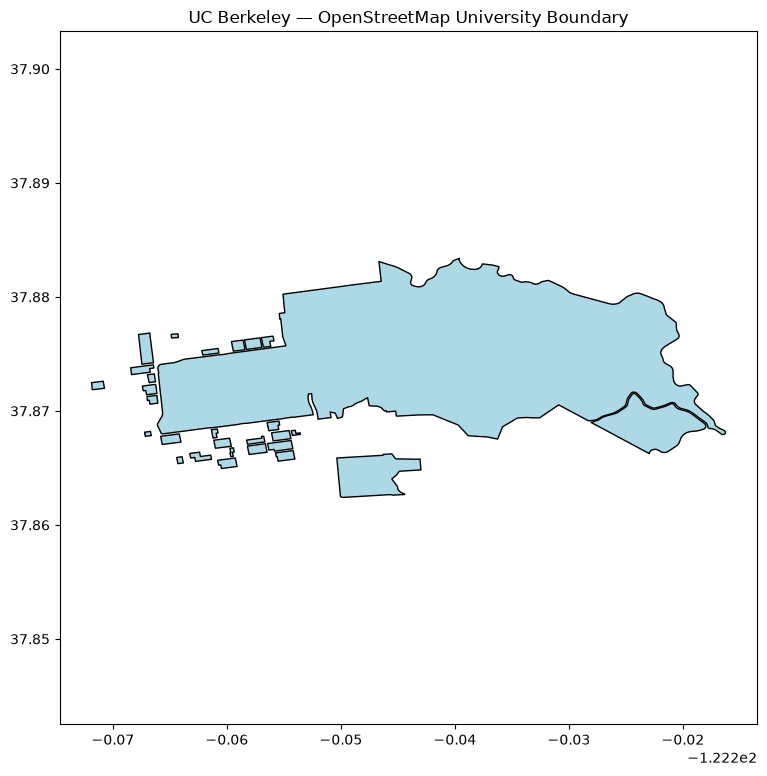

In [6]:
campus_boundary = campus_candidates.loc[
    ("relation", 2814221), "geometry"
]

campus = gpd.GeoDataFrame(
    {"name": ["University of California, Berkeley"]},
    geometry=[campus_boundary],
    crs=campus_candidates.crs
)

campus.plot(
    figsize=(9, 9),
    edgecolor="black",
    facecolor="lightblue"
)
plt.title("UC Berkeley — OpenStreetMap University Boundary")
plt.axis("equal")
plt.show()

In [7]:
buildings = ox.features_from_polygon(
    campus_boundary,
    tags={"building": True}
)

buildings = buildings[
    buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

buildings = buildings[
    buildings.geometry.notna() & ~buildings.geometry.is_empty
].copy()

buildings = gpd.clip(buildings, campus)

print("Buildings in campus boundary:", len(buildings))

Buildings in campus boundary: 458


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: Runt

In [8]:
import pandas as pd
import numpy as np

def parse_height(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip().lower()

    try:
        if "ft" in s or "'" in s:
            s = (
                s.replace("feet", "")
                 .replace("foot", "")
                 .replace("ft", "")
                 .replace("'", "")
                 .strip()
            )
            return float(s) * 0.3048

        s = (
            s.replace("meters", "")
             .replace("meter", "")
             .replace("metres", "")
             .replace("metre", "")
             .replace(" m", "")
             .replace("m", "")
             .strip()
        )
        return float(s)

    except (ValueError, TypeError):
        return np.nan


buildings["height_m"] = buildings["height"].apply(parse_height)

buildings["levels_num"] = pd.to_numeric(
    buildings["building:levels"],
    errors="coerce"
)

buildings["estimated_height_m"] = buildings["height_m"]

use_levels = (
    buildings["estimated_height_m"].isna()
    & buildings["levels_num"].notna()
)

buildings.loc[use_levels, "estimated_height_m"] = (
    buildings.loc[use_levels, "levels_num"] * 3.2
)

buildings["height_source"] = np.select(
    [
        buildings["height_m"].notna(),
        buildings["levels_num"].notna()
    ],
    [
        "Mapped height",
        "Estimated from floor count"
    ],
    default="Unknown"
)

print(buildings["height_source"].value_counts())

height_source
Unknown                       286
Estimated from floor count    166
Mapped height                   6
Name: count, dtype: int64


In [9]:
height_columns = [
    c for c in [
        "name",
        "building",
        "height",
        "building:levels",
        "height_m",
        "estimated_height_m",
        "height_source"
    ]
    if c in buildings.columns
]

display(buildings[height_columns].head(30))

print("\nSummary")
print("Total buildings:", len(buildings))
print("Explicit mapped heights:", buildings["height_m"].notna().sum())
print("Floor counts:", buildings["levels_num"].notna().sum())
print("Unknown heights:", buildings["estimated_height_m"].isna().sum())

# buildings.to_file(
#     "berkeley_campus_buildings.gpkg",
#     layer="buildings",
#     driver="GPKG"
# )

# buildings.drop(columns="geometry").to_csv(
#     "berkeley_campus_building_heights.csv",
#     index=True
# )

name      building   height  \
element  id                                                                   
way      671192885                               NaN        school      NaN   
         183687973          Fenwick Weavers' Village    apartments      NaN   
         183688471       Rochdale Village Building D    apartments      NaN   
         183689093       Rochdale Village Building C    apartments      NaN   
         183688472       Rochdale Village Building E    apartments      NaN   
         183690577       Rochdale Village Building B    apartments      NaN   
         183688276               Rochdale Apartments    apartments      NaN   
         109193722               Beverly Cleary Hall     dormitory      NaN   
         1080852427                              NaN        retail      NaN   
relation 6141724             Maximo Martinez Commons    apartments      NaN   
         9352938                                 NaN        school      NaN   
way      109194851                               NaN        school      NaN   
         109194852       Ellsworth Parking Structure           yes      NaN   
         1011322275                              NaN           yes      NaN   
         1531752525  Bancroft Fulton Student Housing  construction  84.1248   
         545790162                               NaN           yes      NaN   
         24025444                        Tang Center           yes      NaN   
         545790161                               NaN    commercial      NaN   
         109192949                Founder's Building           yes      NaN   
         43150624                    Banway Building    university      NaN   
         41746383                    Ida Sproul Hall     dormitory      NaN   
         41746395                     Priestley Hall     dormitory      NaN   
         41746370                                NaN           yes      NaN   
         431330565                               NaN           yes      NaN   
         431330587                               NaN           yes      NaN   
         41746358                        Norton Hall     dormitory      NaN   
         41746363                   Spens-Black Hall     dormitory      NaN   
         417682513                     Eshleman Hall    university      NaN   
         1037276017                              NaN          roof      NaN   
         24025430                    Zellerbach Hall       theatre      NaN   

                    building:levels  height_m  estimated_height_m  \
element  id                                                         
way      671192885                1       NaN              3.2000   
         183687973              NaN       NaN                 NaN   
         183688471              NaN       NaN                 NaN   
         183689093              NaN       NaN                 NaN   
         183688472              NaN       NaN                 NaN   
         183690577              NaN       NaN                 NaN   
         183688276              NaN       NaN                 NaN   
         109193722              NaN       NaN                 NaN   
         1080852427               1       NaN              3.2000   
relation 6141724                  6       NaN             19.2000   
         9352938                NaN       NaN                 NaN   
way      109194851              NaN       NaN                 NaN   
         109194852              NaN       NaN                 NaN   
         1011322275             NaN       NaN                 NaN   
         1531752525              23   84.1248             84.1248   
         545790162              NaN       NaN                 NaN   
         24025444               NaN       NaN                 NaN   
         545790161              NaN       NaN                 NaN   
         109192949              NaN       NaN                 NaN   
         43150624               NaN       NaN                 NaN   
 


Summary
Total buildings: 458
Explicit mapped heights: 6
Floor counts: 167
Unknown heights: 286


In [10]:
import numpy as np

buildings["viewshed_height_m"] = buildings["estimated_height_m"]

known = buildings["viewshed_height_m"].notna()

print(f"Total buildings: {len(buildings)}")
print(f"Buildings with usable heights: {known.sum()}")
print(f"Buildings with unknown heights: {(~known).sum()}")
print(f"Height coverage: {known.mean() * 100:.1f}%")

Total buildings: 458
Buildings with usable heights: 172
Buildings with unknown heights: 286
Height coverage: 37.6%


In [11]:

import numpy as np
import pandas as pd

buildings["viewshed_height_m"] = pd.to_numeric(
    buildings["estimated_height_m"],
    errors="coerce"
)

buildings["height_imputed"] = (
    buildings["viewshed_height_m"].isna()
)

min_height_m = 70 * 0.3048
max_height_m = 80 * 0.3048
default_height_m = (min_height_m + max_height_m) / 2

buildings.loc[
    buildings["height_imputed"],
    "viewshed_height_m"
] = default_height_m

print("Height imputation summary")
print(f"Buildings: {len(buildings):,}")
print(
    "Buildings with existing estimates:",
    int((~buildings["height_imputed"]).sum())
)
print(
    "Buildings assigned default height:",
    int(buildings["height_imputed"].sum())
)
print(f"Imputed height: {default_height_m:.2f} m")
print(f"Equivalent: {default_height_m / 0.3048:.1f} ft")

print("\nFinal height summary (meters):")
print(buildings["viewshed_height_m"].describe())


Height imputation summary
-------------------------
Buildings: 458
Buildings with existing estimates: 172
Buildings assigned default height: 286
Imputed height: 22.86 m
Equivalent: 75.0 ft

Final height summary (meters):
count    458.000000
mean      19.693198
std        8.353729
min        3.200000
25%       14.500000
50%       22.860000
75%       22.860000
max       93.600000
Name: viewshed_height_m, dtype: float64


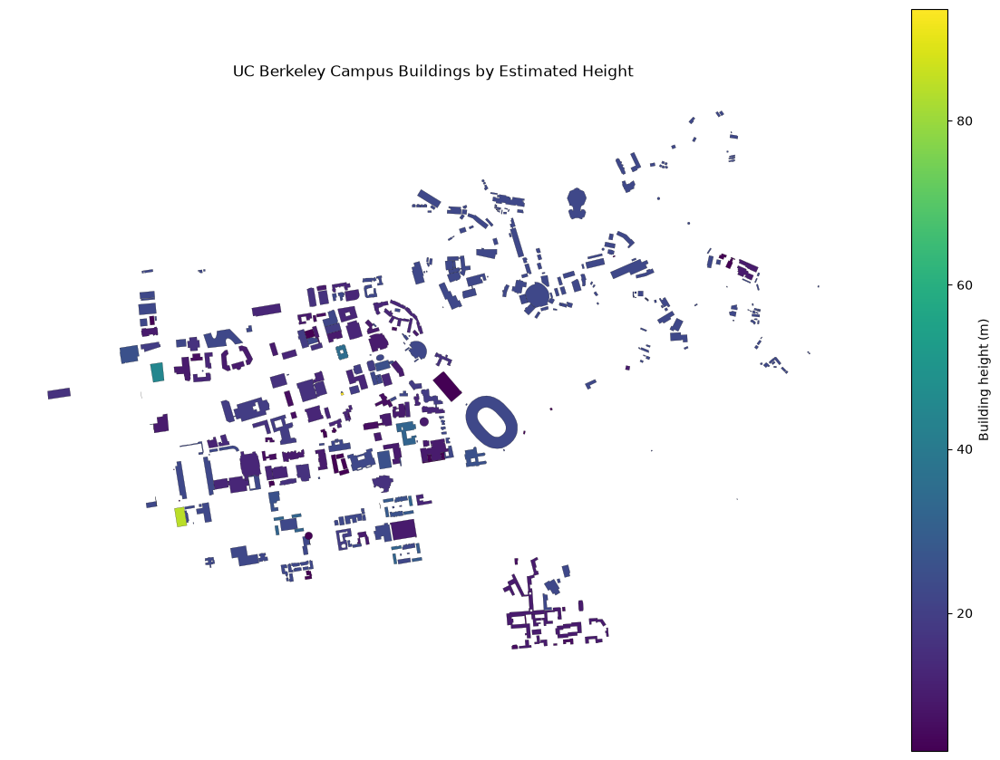

In [12]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors

fig, ax = plt.subplots(figsize=(12, 12))

buildings.plot(
    column="viewshed_height_m",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Building height (m)", "shrink": 0.7},
    edgecolor="black",
    linewidth=0.15,
    ax=ax,
    missing_kwds={"color": "lightgrey"}
)

ax.set_title("UC Berkeley Campus Buildings by Estimated Height")
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [13]:
buildings.to_file(
    "berkeley_campus_buildings_with_heights.gpkg",
    layer="buildings",
    driver="GPKG"
)

## have data now viewshed analysis

In [14]:

import os
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

dem_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/output_USGS10m.tif"
buildings_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_campus_buildings_with_heights.gpkg"

print("DEM exists:", os.path.exists(dem_path))
print("Buildings exist:", os.path.exists(buildings_path))

with rasterio.open(dem_path) as src:
    print("\nDEM CRS:", src.crs)
    print("DEM resolution:", src.res)
    print("DEM bounds:", src.bounds)
    print("DEM dimensions:", src.width, "x", src.height)

buildings = gpd.read_file(buildings_path, layer="buildings")

print("\nBuilding CRS:", buildings.crs)
print("Number of buildings:", len(buildings))
print("Available columns:", buildings.columns.tolist())
print(buildings[["viewshed_height_m"]].describe())


DEM exists: True
Buildings exist: True

DEM CRS: EPSG:4269
DEM resolution: (9.259260000000115e-05, 9.259259999999984e-05)
DEM bounds: BoundingBox(left=-122.27758797529287, bottom=37.8610157880949, right=-122.21258797009287, top=37.8854602344949)
DEM dimensions: 702 x 264

Building CRS: EPSG:4326
Number of buildings: 458
Available columns: ['element', 'id', 'addr:state', 'building', 'ele', 'gnis:feature_id', 'name', 'source', 'note', 'addr:housenumber', 'addr:street', 'building:levels', 'access:disabled', 'air_conditioning', 'amenity', 'internet_access', 'internet_access:fee', 'name:etymology:wikidata', 'name:etymology:wikipedia', 'operator', 'operator:type', 'operator:wikidata', 'website', 'wheelchair', 'wikidata', 'old_name', 'access', 'architect', 'bell_tower', 'bells', 'contact:yelp', 'description', 'display', 'faces', 'height', 'man_made', 'multiple', 'official_name', 'opening_hours', 'sound', 'start_date', 'start_date:bells', 'support', 'tourism', 'tower:construction', 'tower:type

In [15]:

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import rasterize

output_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

height_raster_path = f"{output_dir}/berkeley_building_heights.tif"
surface_path = f"{output_dir}/berkeley_surface_elevation.tif"

with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    profile = src.profile.copy()
    transform = src.transform
    dem_crs = src.crs
    dem_shape = (src.height, src.width)

buildings = buildings.to_crs(dem_crs)

b = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings["viewshed_height_m"].notna()
].copy()

b["viewshed_height_m"] = b["viewshed_height_m"].astype(float)
height_array = rasterize(
    shapes=(
        (geom, float(height))
        for geom, height in zip(
            b.geometry,
            b["viewshed_height_m"]
        )
    ),
    out_shape=dem_shape,
    transform=transform,
    fill=0,
    dtype="float32",
    all_touched=True
)

height_array = np.where(
    np.ma.getmaskarray(dem),
    -9999,
    height_array
).astype("float32")

height_profile = profile.copy()
height_profile.update(
    dtype="float32",
    count=1,
    nodata=-9999,
    compress="lzw"
)

with rasterio.open(height_raster_path, "w", **height_profile) as dst:
    dst.write(height_array, 1)

dem_values = dem.filled(np.nan).astype("float32")
surface = dem_values.copy()

valid = np.isfinite(dem_values)
inside_building = (height_array > 0) & valid

surface[inside_building] += height_array[inside_building]

surface_profile = profile.copy()
surface_profile.update(
    dtype="float32",
    nodata=-9999,
    compress="lzw"
)

surface_to_save = np.where(valid, surface, -9999).astype("float32")

with rasterio.open(surface_path, "w", **surface_profile) as dst:
    dst.write(surface_to_save, 1)

print("Saved building heights:", height_raster_path)
print("Saved terrain + buildings:", surface_path)
print("Buildings included:", len(b))
print("Raster cells covered by buildings:", inside_building.sum())


Saved building heights: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_building_heights.tif
Saved terrain + buildings: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_surface_elevation.tif
Buildings included: 458
Raster cells covered by buildings: 9944


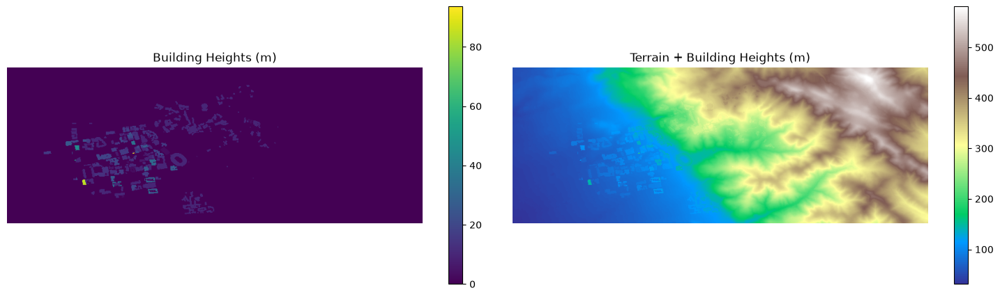

In [16]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

with rasterio.open(height_raster_path) as src:
    heights = src.read(1, masked=True)

with rasterio.open(surface_path) as src:
    surface = src.read(1, masked=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im1 = axes[0].imshow(heights, cmap="viridis", vmin=0)
axes[0].set_title("Building Heights (m)")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], shrink=0.7)

im2 = axes[1].imshow(surface, cmap="terrain")
axes[1].set_title("Terrain + Building Heights (m)")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], shrink=0.7)

plt.tight_layout()
plt.show()


In [17]:

import os
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.features import rasterize
from rasterio.transform import rowcol

dem_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/output_USGS10m.tif"
buildings_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_campus_buildings_with_heights.gpkg"

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"
projected_dem_path = f"{out_dir}/berkeley_dem_utm10n.tif"
height_path = f"{out_dir}/berkeley_building_heights_utm10n.tif"
surface_path = f"{out_dir}/berkeley_surface_utm10n.tif"

target_crs = "EPSG:26910"

with rasterio.open(dem_path) as src:
    transform, width, height = calculate_default_transform(
        src.crs, target_crs, src.width, src.height, *src.bounds,
        resolution=10
    )
    profile = src.profile.copy()
    profile.update(
        crs=target_crs,
        transform=transform,
        width=width,
        height=height,
        dtype="float32",
        count=1,
        nodata=-9999,
        compress="lzw"
    )

    with rasterio.open(projected_dem_path, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=target_crs,
            dst_nodata=-9999,
            resampling=Resampling.bilinear
        )

buildings = gpd.read_ile(buildings_path, layer="buildings").to_crs(target_crs)
buildings = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings["viewshed_height_m"].notna()
].copy()

with rasterio.open(projected_dem_path) as src:
    dem = src.read(1)
    valid = (dem != src.nodata) & np.isfinite(dem)
    profile = src.profile.copy()
    transform = src.transform
    shape = dem.shape

height_array = rasterize(
    (
        (geom, float(h))
        for geom, h in zip(
            buildings.geometry,
            buildings["viewshed_height_m"]
        )
    ),
    out_shape=shape,
    transform=transform,
    fill=0,
    dtype="float32",
    all_touched=True
)

height_array[~valid] = -9999

with rasterio.open(height_path, "w", **profile) as dst:
    dst.write(height_array, 1)

surface = np.full(shape, -9999, dtype="float32")
surface[valid] = dem[valid]
inside = valid & (height_array > 0)
surface[inside] += height_array[inside]

surface_profile = profile.copy()
surface_profile.update(compress="lzw")

with rasterio.open(surface_path, "w", **surface_profile) as dst:
    dst.write(surface, 1)

print("Projected DEM:", projected_dem_path)
print("Building heights:", height_path)
print("Combined surface:", surface_path)
print("Grid size:", width, "x", height)


Projected DEM: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_dem_utm10n.tif
Building heights: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_building_heights_utm10n.tif
Combined surface: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_surface_utm10n.tif
Grid size: 574 x 276


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/3360596474.py:60: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = src.read(1)


In [18]:
from osgeo import gdal
print("GDAL version:", gdal.VersionInfo("--version"))

GDAL version: GDAL 3.11.4 "Eganville", released 2025/09/04


In [19]:

import os
import numpy as np
import rasterio
import geopandas as gpd

from osgeo import gdal
from rasterio.transform import rowcol
from rasterio.features import geometry_mask

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

dem_path = f"{out_dir}/berkeley_dem_utm10n.tif"
surface_path = f"{out_dir}/berkeley_surface_utm10n.tif"

surface_tower_path = f"{out_dir}/berkeley_surface_with_campanile_top.tif"
viewshed_path = f"{out_dir}/campanile_pedestrian_visibility.tif"

campanile_lon = -122.2577
campanile_lat = 37.8721

tower_height_m = 93.6

pedestrian_eye_height_m = 1.7

point = gpd.GeoDataFrame(
    {"name": ["Campanile"]},
    geometry=gpd.points_from_xy(
        [campanile_lon], [campanile_lat]
    ),
    crs="EPSG:4326"
).to_crs("EPSG:26910")

tower_x = point.geometry.iloc[0].x
tower_y = point.geometry.iloc[0].y

with rasterio.open(dem_path) as dem_src:
    dem = dem_src.read(1)
    profile = dem_src.profile.copy()
    transform = dem_src.transform
    nodata = dem_src.nodata

    row, col = rowcol(transform, tower_x, tower_y)

    if not (0 <= row < dem_src.height and 0 <= col < dem_src.width):
        raise ValueError(
            "Campanile point is outside the DEM. Check its coordinates."
        )

    ground_elevation = float(dem[row, col])

    if nodata is not None and np.isclose(ground_elevation, nodata):
        raise ValueError("Campanile point falls on a NoData DEM cell.")

with rasterio.open(surface_path) as src:
    surface = src.read(1)
    surface_profile = src.profile.copy()
    surface_nodata = src.nodata


surface[row, col] = ground_elevation + tower_height_m

with rasterio.open(surface_tower_path, "w", **surface_profile) as dst:
    dst.write(surface, 1)


src_ds = gdal.Open(surface_tower_path, gdal.GA_ReadOnly)

if src_ds is None:
    raise RuntimeError("Could not open the surface raster with GDAL.")

band = src_ds.GetRasterBand(1)
driver = gdal.GetDriverByName("GTiff")

result_ds = gdal.ViewshedGenerate(
    band,
    "GTiff",
    viewshed_path,
    ["COMPRESS=LZW"],
    tower_x,
    tower_y,
    0.0,                         
    pedestrian_eye_height_m,     
    1,                          
    0,                          
    0,                          
    255,                       
    0.0,                        
    gdal.GVOT_NORMAL,
    0.0                        
)

if result_ds is None:
    raise RuntimeError("GDAL did not create a viewshed raster.")

result_ds = None
src_ds = None

if "campus" not in globals():
    raise NameError(
        "The campus GeoDataFrame is not in memory. "
        "Reload or recreate your campus boundary first."
    )

campus_projected = campus.to_crs("EPSG:26910")

with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    height, width = src.height, src.width

inside_campus = geometry_mask(
    campus_projected.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

visibility[~inside_campus] = 255

profile.update(dtype="uint8", nodata=255, compress="lzw")

with rasterio.open(viewshed_path, "w", **profile) as dst:
    dst.write(visibility.astype("uint8"), 1)

print("Viewshed saved:", viewshed_path)
print("Campanile ground elevation:", round(ground_elevation, 2), "m")
print("Approximate tower-top elevation:",
      round(ground_elevation + tower_height_m, 2), "m")
print("Visible cells inside campus:",
      int(np.sum((visibility == 1) & inside_campus)))


Viewshed saved: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/campanile_pedestrian_visibility.tif
Campanile ground elevation: 98.52 m
Approximate tower-top elevation: 192.12 m
Visible cells inside campus: 22403


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/40496169.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = dem_src.read(1)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/40496169.py:61: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  surface = src.read(1)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/osgeo/gdal.py:330: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/osgeo/gdal.py:9351: RuntimeWarning: Nodata value found in input DEM. Output will be likely incorrect
  return _gdal.Views

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/1455153921.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visibility = src.read(1)


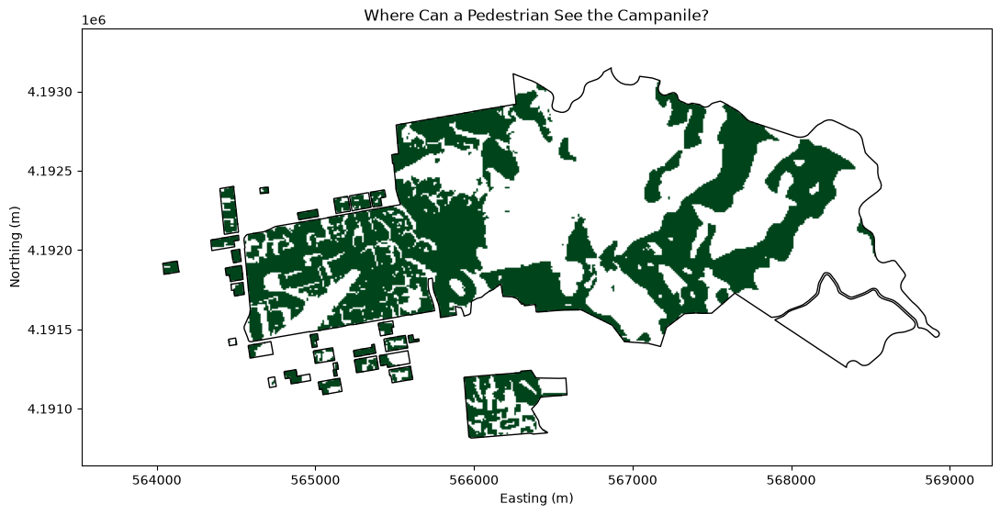

In [20]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    extent = (
        src.bounds.left, src.bounds.right,
        src.bounds.bottom, src.bounds.top
    )

visible = np.ma.masked_where(
    (visibility != 1) | (visibility == 255),
    visibility
)

fig, ax = plt.subplots(figsize=(11, 11))

ax.imshow(
    visible,
    extent=extent,
    origin="upper",
    cmap="Greens",
    vmin=0,
    vmax=1
)

campus_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

ax.set_title("Where Can a Pedestrian See the Campanile?")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [21]:

import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.features import rasterize, geometry_mask

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

viewshed_path = f"{out_dir}/campanile_pedestrian_visibility.tif"
ground_viewshed_path = f"{out_dir}/campanile_visible_pedestrian_ground.tif"

with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    shape = (src.height, src.width)
    crs = src.crs
    bounds = src.bounds

buildings_projected = buildings.to_crs(crs)


building_mask = rasterize(
    (
        (geom, 1)
        for geom in buildings_projected.geometry
        if geom is not None and not geom.is_empty
    ),
    out_shape=shape,
    transform=transform,
    fill=0,
    dtype="uint8",
    all_touched=True
)

campus_mask = geometry_mask(
    campus_projected.geometry,
    out_shape=shape,
    transform=transform,
    invert=True,
    all_touched=False
)


visible_ground = (
    (visibility == 1)
    & campus_mask
    & (building_mask == 0)
)


result = np.zeros(shape, dtype="uint8")
result[visible_ground] = 1
result[~campus_mask] = 255

profile.update(dtype="uint8", count=1, nodata=255, compress="lzw")

with rasterio.open(ground_viewshed_path, "w", **profile) as dst:
    dst.write(result, 1)

print("Saved:", ground_viewshed_path)
print("Visible ground cells:", int(visible_ground.sum()))
print("Building footprint cells removed:", int(building_mask.sum()))


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/718489887.py:15: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visibility = src.read(1)


Saved: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/campanile_visible_pedestrian_ground.tif
Visible ground cells: 16127
Building footprint cells removed: 8634


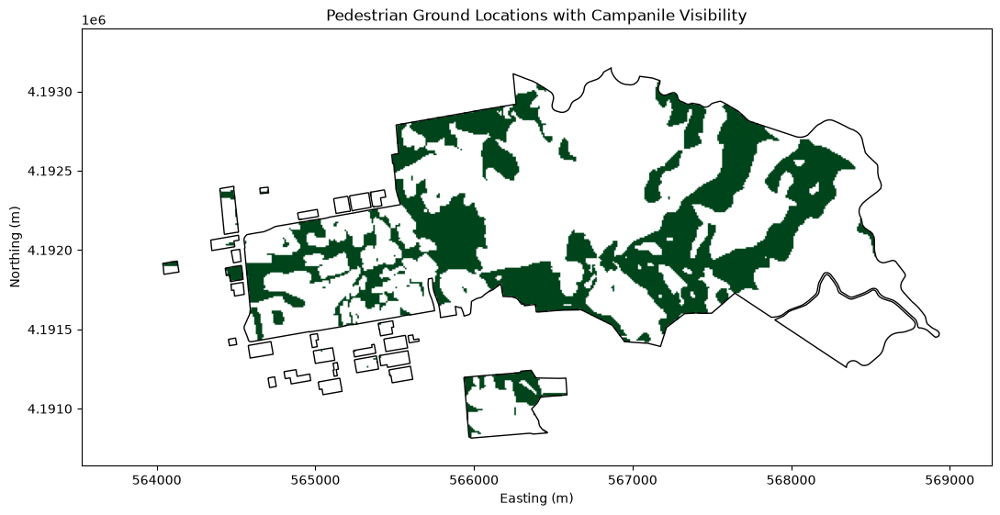

In [22]:

fig, ax = plt.subplots(figsize=(11, 11))

visible = np.ma.masked_where(result != 1, result)

ax.imshow(
    visible,
    extent=(bounds.left, bounds.right, bounds.bottom, bounds.top),
    origin="upper",
    cmap="Greens",
    vmin=0,
    vmax=1
)

campus_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

ax.set_title("Pedestrian Ground Locations with Campanile Visibility")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


# Plotting this

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/140683887.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = np.array(src.read(1), dtype=np.float32, copy=True)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/140683887.py:72: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visible_ground = np.array(src.read(1), copy=True)


DEM shape: (276, 574)
X coordinate shape: (276, 574)
Y coordinate shape: (276, 574)
Visible ground cells: 16127
Buildings loaded: 458
DEM CRS: EPSG:26910
DEM dimensions: 574 columns × 276 rows
Finished adding solid building geometry.


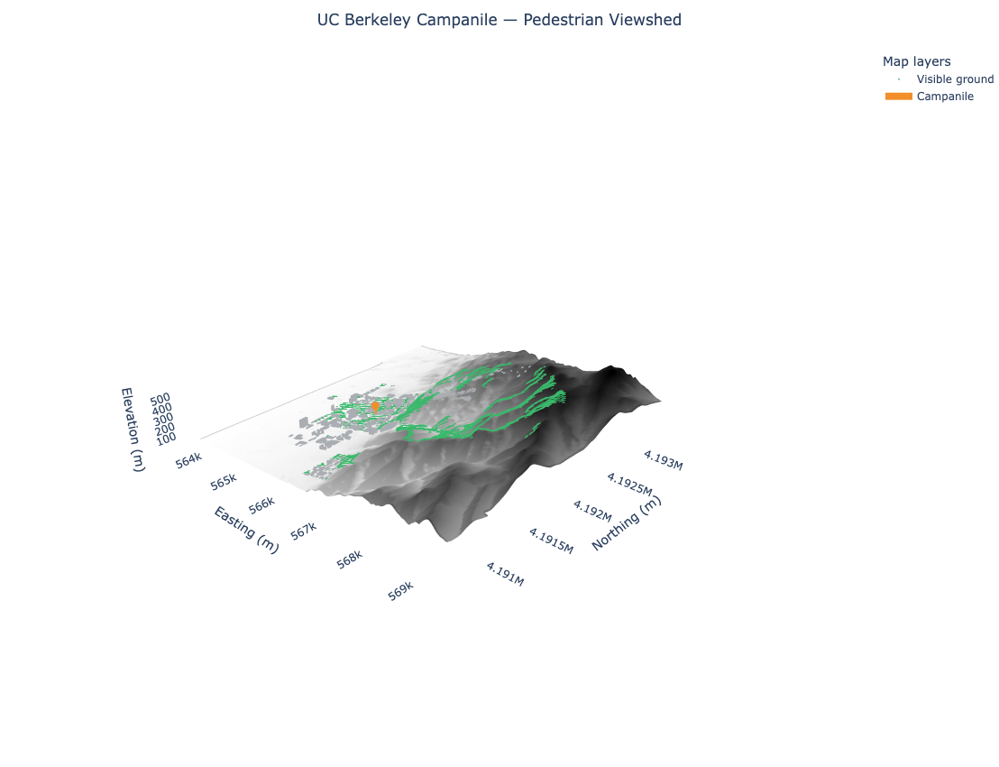

In [23]:
import os
import numpy as np
import geopandas as gpd
import rasterio
import plotly.graph_objects as go

from shapely.geometry import Polygon, MultiPolygon
from rasterio.warp import reproject, Resampling


output_dir = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs"
)

dem_path = os.path.join(output_dir, "berkeley_dem_utm10n.tif")

buildings_path = os.path.join(
    output_dir,
    "berkeley_campus_buildings_with_heights.gpkg"
)

viewshed_path = os.path.join(
    output_dir,
    "campanile_pedestrian_visibility.tif"
)

visible_ground_path = os.path.join(
    output_dir,
    "campanile_visible_pedestrian_ground.tif"
)


with rasterio.open(dem_path) as src:
    dem = np.array(src.read(1), dtype=np.float32, copy=True)
    dem_transform = src.transform
    dem_crs = src.crs
    dem_bounds = src.bounds
    dem_nodata = src.nodata

if dem_nodata is not None:
    dem[dem == dem_nodata] = np.nan

dem[~np.isfinite(dem)] = np.nan

rows, cols = np.indices(dem.shape)

x_coords = (
    dem_transform.c
    + (cols + 0.5) * dem_transform.a
    + (rows + 0.5) * dem_transform.b
)

y_coords = (
    dem_transform.f
    + (cols + 0.5) * dem_transform.d
    + (rows + 0.5) * dem_transform.e
)

with rasterio.open(visible_ground_path) as src:
    visible_ground = np.array(src.read(1), copy=True)
    visible_transform = src.transform
    visible_crs = src.crs
    visible_nodata = src.nodata

if (
    visible_ground.shape != dem.shape
    or visible_transform != dem_transform
    or visible_crs != dem_crs
):
    visible_ground_aligned = np.zeros(dem.shape, dtype=np.uint8)

    with rasterio.open(visible_ground_path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=visible_ground_aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=dem_transform,
            dst_crs=dem_crs,
            resampling=Resampling.nearest,
            src_nodata=src.nodata,
            dst_nodata=0
        )

    visible_ground = visible_ground_aligned

visible_mask = (visible_ground == 1) & np.isfinite(dem)

# Extract visible coordinates and elevations
visible_x = x_coords[visible_mask]
visible_y = y_coords[visible_mask]
visible_z = dem[visible_mask]

print("DEM shape:", dem.shape)
print("X coordinate shape:", x_coords.shape)
print("Y coordinate shape:", y_coords.shape)
print("Visible ground cells:", len(visible_x))


buildings = gpd.read_file(
    buildings_path,
    layer="buildings"
)

if buildings.crs != dem_crs:
    buildings = buildings.to_crs(dem_crs)

buildings["viewshed_height_m"] = (
    gpd.pd.to_numeric(
        buildings["viewshed_height_m"],
        errors="coerce"
    )
)

# Fill missing heights with the same provisional default
# used in the earlier building-height workflow
buildings["viewshed_height_m"] = (
    buildings["viewshed_height_m"].fillna(10.0)
)

# Remove invalid or empty footprints
buildings = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
].copy()

print(f"Buildings loaded: {len(buildings):,}")
print(f"DEM CRS: {dem_crs}")
print(f"DEM dimensions: {dem.shape[1]} columns × {dem.shape[0]} rows")

def get_ground_elevation(geometry, dem_array, transform):
    """
    Estimate the building base elevation from the DEM near
    the footprint centroid. If that pixel is invalid, use
    the median of valid pixels in the surrounding 3x3 window.
    """
    centroid = geometry.centroid

    row, col = rasterio.transform.rowcol(
        transform,
        centroid.x,
        centroid.y
    )

    if (
        0 <= row < dem_array.shape[0]
        and 0 <= col < dem_array.shape[1]
    ):
        value = dem_array[row, col]

        if np.isfinite(value):
            return float(value)

        r0 = max(0, row - 1)
        r1 = min(dem_array.shape[0], row + 2)
        c0 = max(0, col - 1)
        c1 = min(dem_array.shape[1], col + 2)

        window = dem_array[r0:r1, c0:c1]
        valid = window[np.isfinite(window)]

        if valid.size:
            return float(np.median(valid))

    # Last-resort fallback if no DEM value is available
    return 0.0

def add_solid_building(
    fig,
    polygon,
    base_z,
    height,
    color="#D5D9DF",
    wall_opacity=1.0,
    roof_opacity=1.0
):
    """
    Draw a building as vertical walls plus a flat roof.

    Intended for simple building footprints without interior
    holes. MultiPolygon geometries are handled separately.
    """
    if polygon.is_empty or polygon.geom_type != "Polygon":
        return
    bx, by = polygon.exterior.xy
    bx = np.asarray(bx[:-1], dtype=float)
    by = np.asarray(by[:-1], dtype=float)

    if len(bx) < 3:
        return

    roof_z = base_z + max(float(height), 1.0)
    n = len(bx)


    center_x = float(np.mean(bx))
    center_y = float(np.mean(by))

    roof_x = list(bx) + [center_x]
    roof_y = list(by) + [center_y]
    roof_z_values = [roof_z] * n + [roof_z]

    center_idx = n

    i = list(range(n))
    j = [(idx + 1) % n for idx in range(n)]
    k = [center_idx] * n

    fig.add_trace(
        go.Mesh3d(
            x=roof_x,
            y=roof_y,
            z=roof_z_values,
            i=i,
            j=j,
            k=k,
            color=color,
            opacity=roof_opacity,
            flatshading=True,
            showscale=False,
            hoverinfo="skip",
            name="Building roofs",
            showlegend=False
        )
    )


    wall_x = []
    wall_y = []
    wall_z = []
    wall_i = []
    wall_j = []
    wall_k = []

    for idx in range(n):
        nxt = (idx + 1) % n
        x1, y1 = bx[idx], by[idx]
        x2, y2 = bx[nxt], by[nxt]

        start = len(wall_x)

        wall_x.extend([x1, x2, x2, x1])
        wall_y.extend([y1, y2, y2, y1])
        wall_z.extend([
            base_z,
            base_z,
            roof_z,
            roof_z
        ])
        wall_i.extend([start, start])
        wall_j.extend([start + 1, start + 2])
        wall_k.extend([start + 2, start + 3])

    fig.add_trace(
        go.Mesh3d(
            x=wall_x,
            y=wall_y,
            z=wall_z,
            i=wall_i,
            j=wall_j,
            k=wall_k,
            color=color,
            opacity=wall_opacity,
            flatshading=True,
            showscale=False,
            hoverinfo="skip",
            name="Building walls",
            showlegend=False
        )
    )


fig = go.Figure()
terrain_step = 3

fig.add_trace(
    go.Surface(
        x=x_coords[::terrain_step, ::terrain_step],
        y=y_coords[::terrain_step, ::terrain_step],
        z=dem[::terrain_step, ::terrain_step],
        colorscale="Greys",
        showscale=False,
        opacity=1.0,
        name="Terrain",
        hovertemplate=(
            "Easting: %{x:.1f} m<br>"
            "Northing: %{y:.1f} m<br>"
            "Elevation: %{z:.1f} m"
            "<extra>Terrain</extra>"
        )
    )
)marker_step = 3

visible_x_plot = visible_x[::marker_step]
visible_y_plot = visible_y[::marker_step]
visible_z_plot = visible_z[::marker_step]

fig.add_trace(
    go.Scatter3d(
        x=visible_x_plot,
        y=visible_y_plot,
        z=visible_z_plot + 0.35,
        mode="markers",
        marker=dict(
            size=2,
            color="#39B96B",
            opacity=0.85
        ),
        name="Visible ground",
        hoverinfo="skip"
    )
)

with rasterio.open(dem_path) as dem_src:

    for _, row in buildings.iterrows():

        geometry = row.geometry
        height = row["viewshed_height_m"]

        if geometry is None or geometry.is_empty:
            continue

        if not np.isfinite(height) or height <= 0:
            height = 10.0
        base_z = get_ground_elevation(
            geometry,
            dem,
            dem_transform
        )
        if geometry.geom_type == "Polygon":
            polygons = [geometry]

        elif geometry.geom_type == "MultiPolygon":
            polygons = list(geometry.geoms)

        else:
            continue

        for polygon in polygons:
            add_solid_building(
                fig=fig,
                polygon=polygon,
                base_z=base_z,
                height=height,
                color="#D5D9DF",
                wall_opacity=1.0,
                roof_opacity=1.0
            )

print("Finished adding solid building geometry.")

campanile_lon = -122.2577
campanile_lat = 37.8721

from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    dem_crs,
    always_xy=True
)

campanile_x, campanile_y = transformer.transform(
    campanile_lon,
    campanile_lat
)

campanile_base_z = get_ground_elevation(
    gpd.GeoSeries(
        [gpd.points_from_xy([campanile_x], [campanile_y])[0]],
        crs=dem_crs
    ).iloc[0],
    dem,
    dem_transform
)

campanile_height = 93.6
campanile_top_z = campanile_base_z + campanile_height

fig.add_trace(
    go.Scatter3d(
        x=[campanile_x, campanile_x],
        y=[campanile_y, campanile_y],
        z=[campanile_base_z, campanile_top_z],
        mode="lines",
        line=dict(
            color="#F28E2B",
            width=8
        ),
        name="Campanile",
        hovertemplate=(
            "Sather Tower (Campanile)<br>"
            "Height: 93.6 m"
            "<extra></extra>"
        )
    )
)

fig.add_trace(
    go.Scatter3d(
        x=[campanile_x],
        y=[campanile_y],
        z=[campanile_top_z],
        mode="markers",
        marker=dict(
            size=5,
            color="#F28E2B"
        ),
        showlegend=False,
        hoverinfo="skip"
    )
)


fig.update_layout(
    title=dict(
        text="UC Berkeley Campanile — Pedestrian Viewshed",
        x=0.5
    ),
    scene=dict(
        xaxis=dict(
            title="Easting (m)",
            showbackground=False,
            showgrid=False
        ),
        yaxis=dict(
            title="Northing (m)",
            showbackground=False,
            showgrid=False
        ),
        zaxis=dict(
            title="Elevation (m)",
            showbackground=False,
            showgrid=True
        ),
        aspectmode="manual",
        aspectratio=dict(
            x=1,
            y=1,
            z=0.18
        ),
        camera=dict(
            eye=dict(
                x=1.5,
                y=-1.6,
                z=1.1
            )
        )
    ),
    legend=dict(
        title="Map layers"
    ),
    margin=dict(
        l=0,
        r=0,
        t=55,
        b=0
    ),
    height=850
)

fig.show()

# fix the stadium and the building heights

In [24]:

stadium_mask = (
    buildings["building"].astype(str).str.lower() == "stadium"
)

print(
    buildings.loc[
        stadium_mask,
        [
            "building",
            "height",
            "height_m",
            "estimated_height_m",
            "height_source",
            "height_imputed",
            "viewshed_height_m"
        ]
    ].to_string()
)


    building height  height_m  estimated_height_m height_source  height_imputed  viewshed_height_m
37   stadium    NaN       NaN                 NaN       Unknown            True               10.0
38   stadium    NaN       NaN                 NaN       Unknown            True               10.0
272  stadium    NaN       NaN                 NaN       Unknown            True               10.0


In [25]:

# Update all three stadium footprint records
stadium_mask = (
    buildings["building"].astype(str).str.lower() == "stadium"
)

buildings.loc[stadium_mask, "viewshed_height_m"] = 20.4

# Mark these as manually adjusted, not generic imputations
buildings.loc[stadium_mask, "height_source"] = (
    "Manual stadium-specific approximation"
)

print(
    buildings.loc[
        stadium_mask,
        ["building", "viewshed_height_m", "height_source"]
    ].to_string()
)


    building  viewshed_height_m                          height_source
37   stadium               20.4  Manual stadium-specific approximation
38   stadium               20.4  Manual stadium-specific approximation
272  stadium               20.4  Manual stadium-specific approximation


In [26]:

# Recreate heights from the original estimates
buildings["viewshed_height_m"] = pd.to_numeric(
    buildings["estimated_height_m"],
    errors="coerce"
)

# Fill missing estimates with the midpoint of 45–70 ft
default_height_m = ((60 + 85) / 2) * 0.3048

missing_height = buildings["viewshed_height_m"].isna()

buildings.loc[missing_height, "viewshed_height_m"] = default_height_m

# Apply the stadium override after general imputation
stadium_mask = (
    buildings["building"].astype(str).str.lower() == "stadium"
)

buildings.loc[stadium_mask, "viewshed_height_m"] = 20.4

print("Default for missing heights:", round(default_height_m, 2), "m")
print("Remaining missing heights:", buildings["viewshed_height_m"].isna().sum())
print("Buildings still at 10 m:", (buildings["viewshed_height_m"] == 10).sum())


Default for missing heights: 22.1 m
Remaining missing heights: 0
Buildings still at 10 m: 0


Stadium footprint features: 3
Stadium heights (m): [20.4, 20.4, 20.4]


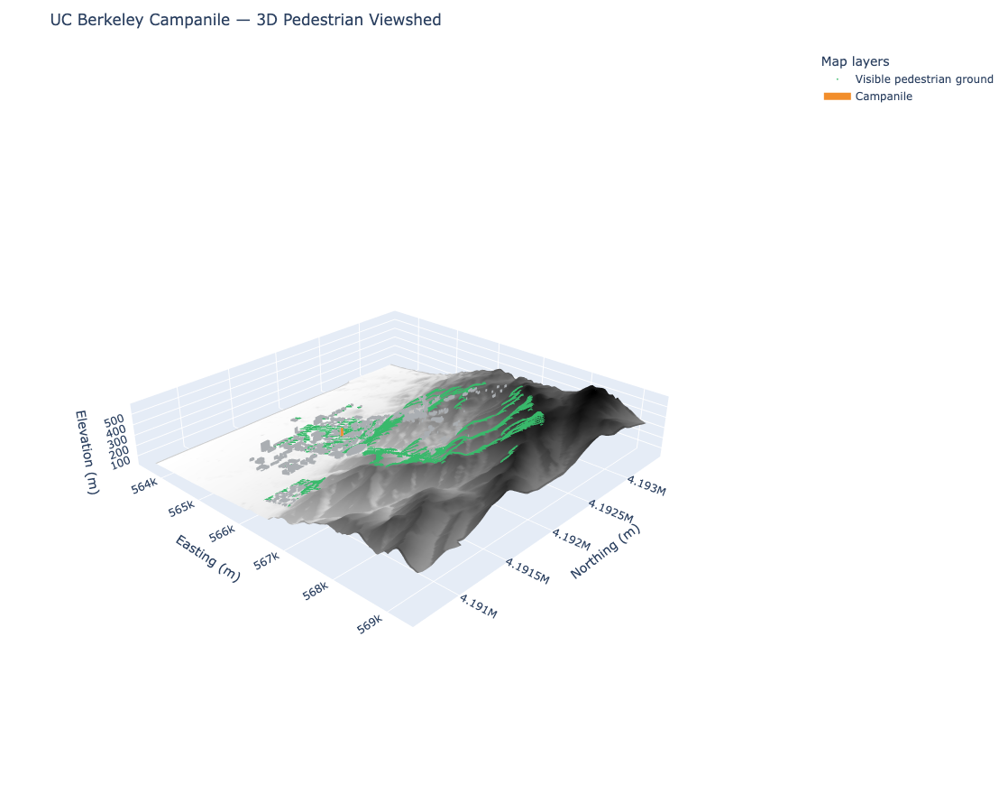

In [27]:
import numpy as np
import plotly.graph_objects as go
from pyproj import Transformer
from shapely.geometry import Point, Polygon, MultiPolygon

fig = go.Figure()

terrain_step = 3

fig.add_trace(
    go.Surface(
        x=x_coords[::terrain_step, ::terrain_step],
        y=y_coords[::terrain_step, ::terrain_step],
        z=dem[::terrain_step, ::terrain_step],
        colorscale="Greys",
        showscale=False,
        name="Terrain",
        hoverinfo="skip"
    )
)

fig.add_trace(
    go.Scatter3d(
        x=visible_x,
        y=visible_y,
        z=visible_z + 0.35,
        mode="markers",
        marker=dict(size=2, color="#39B96B", opacity=0.85),
        name="Visible pedestrian ground",
        hoverinfo="skip"
    )
)

for _, row in buildings.iterrows():
    geom = row.geometry
    height = row["viewshed_height_m"]

    if geom is None or geom.is_empty:
        continue

    if not np.isfinite(height) or height <= 0:
        continue

    base_z = get_ground_elevation(geom, dem, dem_transform)

    if geom.geom_type == "Polygon":
        polygons = [geom]
    elif geom.geom_type == "MultiPolygon":
        polygons = list(geom.geoms)
    else:
        continue

    for poly in polygons:
        add_solid_building(
            fig=fig,
            polygon=poly,
            base_z=base_z,
            height=height,
            color="#D5D9DF",
            wall_opacity=1.0,
            roof_opacity=1.0
        )

stadium_mask = (
    buildings["building"].astype(str).str.lower() == "stadium"
)

stadium_buildings = buildings.loc[stadium_mask]

print(f"Stadium footprint features: {len(stadium_buildings)}")
print(
    "Stadium heights (m):",
    stadium_buildings["viewshed_height_m"].tolist()
)

transformer = Transformer.from_crs(
    "EPSG:4326",
    dem_crs,
    always_xy=True
)

campanile_x, campanile_y = transformer.transform(
    -122.2577,
    37.8721
)

campanile_base_z = get_ground_elevation(
    Point(campanile_x, campanile_y),
    dem,
    dem_transform
)

campanile_top_z = campanile_base_z + 93.6

fig.add_trace(
    go.Scatter3d(
        x=[campanile_x, campanile_x],
        y=[campanile_y, campanile_y],
        z=[campanile_base_z, campanile_top_z],
        mode="lines",
        line=dict(color="#F28E2B", width=8),
        name="Campanile"
    )
)

fig.update_layout(
    title="UC Berkeley Campanile — 3D Pedestrian Viewshed",
    scene=dict(
        xaxis_title="Easting (m)",
        yaxis_title="Northing (m)",
        zaxis_title="Elevation (m)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.18),
        camera=dict(eye=dict(x=1.5, y=-1.6, z=1.1))
    ),
    height=900,
    margin=dict(l=0, r=0, t=55, b=0),
    legend=dict(title="Map layers")
)

fig.show()

In [29]:

from osgeo import gdal

observer_row, observer_col = rowcol(
    transform,
    campanile_x,
    campanile_y
)

if not (
    0 <= observer_row < dem.shape[0]
    and 0 <= observer_col < dem.shape[1]
):
    raise ValueError("Campanile observer point falls outside the DEM.")

observer_ground_z = float(dem[observer_row, observer_col])

if not np.isfinite(observer_ground_z):
    raise ValueError("DEM elevation at the Campanile is invalid.")

print("Observer ground elevation:", observer_ground_z, "m")
print("Observer height above ground:", campanile_height_m, "m")
print("Target pedestrian eye height:", pedestrian_eye_height_m, "m")

surface_ds = gdal.Open(surface_path, gdal.GA_ReadOnly)

if surface_ds is None:
    raise RuntimeError(f"Could not open surface raster: {surface_path}")

if os.path.exists(viewshed_path):
    os.remove(viewshed_path)

result = gdal.ViewshedGenerate(
    surface_ds.GetRasterBand(1),
    "GTiff",
    viewshed_path,
    [],
    float(campanile_x),
    float(campanile_y),
    float(campanile_height_m),
    float(pedestrian_eye_height_m),
    1,
    0,
    0,
    255,
    0,
    gdal.GVM_Edge,
    0
)

surface_ds = None

if result is None:
    raise RuntimeError("GDAL failed to generate the viewshed.")

result = None

print("Updated viewshed saved to:")
print(viewshed_path)

Observer ground elevation: 98.5167236328125 m
Observer height above ground: 93.6 m
Target pedestrian eye height: 1.7 m
Updated viewshed saved to:
/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/campanile_pedestrian_visibility.tif


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/osgeo/gdal.py:9351: RuntimeWarning: Nodata value found in input DEM. Output will be likely incorrect
  return _gdal.ViewshedGenerate(*args, **kwargs)


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/202949497.py:12: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem_map = src.read(1).astype(float)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/202949497.py:21: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visible_ground = src.read(1)


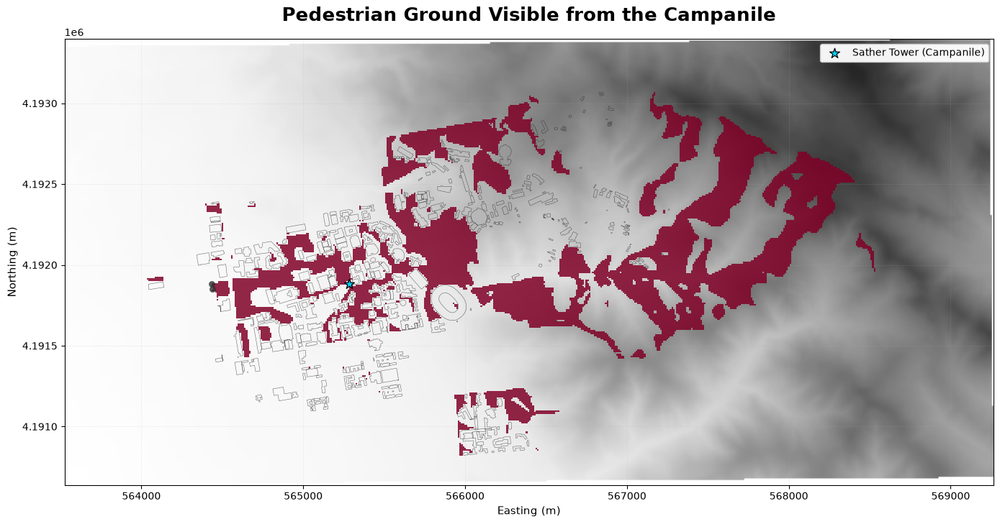

In [30]:
import os
import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.plot import plotting_extent

with rasterio.open(dem_path) as src:
    dem_map = src.read(1).astype(float)
    dem_transform = src.transform
    dem_crs = src.crs
    dem_extent = plotting_extent(src)

    if src.nodata is not None:
        dem_map[dem_map == src.nodata] = np.nan

with rasterio.open(visible_ground_path) as src:
    visible_ground = src.read(1)
    visible_extent = plotting_extent(src)

visible_mask = np.ma.masked_where(
    (visible_ground != 1) | ~np.isfinite(dem_map),
    visible_ground
)
if "buildings" in globals():
    buildings_map = buildings.to_crs(dem_crs).copy()
else:
    buildings_map = gpd.read_file(
        buildings_path,
        layer="buildings"
    ).to_crs(dem_crs)
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    dem_crs,
    always_xy=True
)

campanile_x, campanile_y = transformer.transform(
    -122.2577,
    37.8721
)
fig, ax = plt.subplots(figsize=(14, 12))

ax.imshow(
    dem_map,
    extent=dem_extent,
    origin="upper",
    cmap="Greys",
    alpha=0.85,
    zorder=1
)

ax.imshow(
    visible_mask,
    extent=visible_extent,
    origin="upper",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    alpha=0.85,
    interpolation="nearest",
    zorder=2
)

buildings_map.boundary.plot(
    ax=ax,
    color="#303030",
    linewidth=0.35,
    alpha=0.8,
    zorder=3
)

ax.scatter(
    campanile_x,
    campanile_y,
    s=110,
    marker="*",
    color="#00D5FF",
    edgecolor="black",
    linewidth=0.9,
    zorder=5,
    label="Sather Tower (Campanile)"
)

# Map styling
ax.set_title(
    "Pedestrian Ground Visible from the Campanile",
    fontsize=19,
    pad=18,
    weight="bold"
)

ax.set_xlabel("Easting (m)", fontsize=11)
ax.set_ylabel("Northing (m)", fontsize=11)
ax.set_aspect("equal")

ax.legend(
    loc="upper right",
    frameon=True,
    framealpha=0.95
)

ax.grid(
    visible=True,
    linestyle="--",
    linewidth=0.4,
    alpha=0.3
)

plt.tight_layout()
plt.show()

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/2011366687.py:14: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = src.read(1).astype(float)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/2011366687.py:24: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visible = src.read(1)


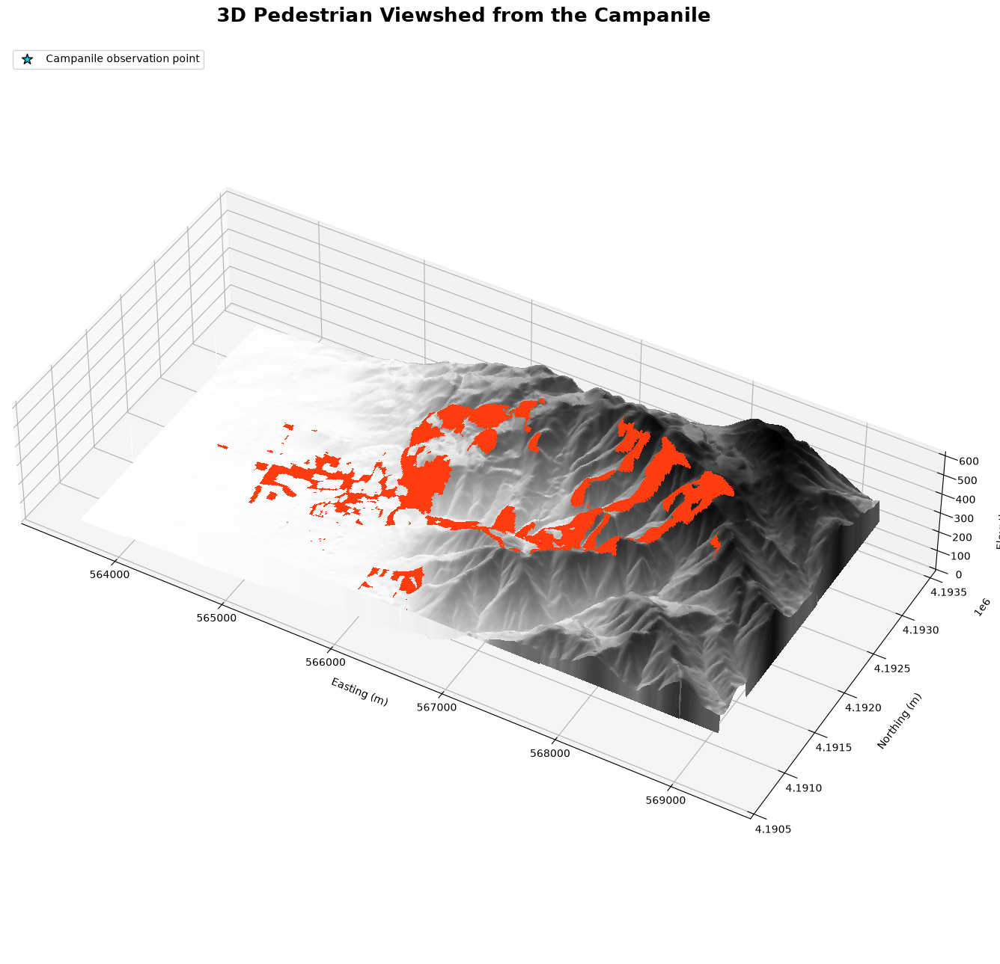

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.enums import Resampling
from pyproj import Transformer
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import LightSource

with rasterio.open(dem_path) as src:
    dem = src.read(1).astype(float)
    transform = src.transform
    dem_crs = src.crs
    bounds = src.bounds
    nodata = src.nodata

    if nodata is not None:
        dem[dem == nodata] = np.nan

with rasterio.open(visible_ground_path) as src:
    visible = src.read(1)

max_dim = 700
stride = max(1, int(np.ceil(max(dem.shape) / max_dim)))

dem_3d = dem[::stride, ::stride]
visible_3d = visible[::stride, ::stride]

rows, cols = dem_3d.shape
x = transform.c + (np.arange(cols) * stride + 0.5) * transform.a
y = transform.f + (np.arange(rows) * stride + 0.5) * transform.e
X, Y = np.meshgrid(x, y)

ls = LightSource(azdeg=315, altdeg=45)
safe_dem = np.where(np.isfinite(dem_3d), dem_3d, np.nanmedian(dem_3d))

terrain_rgb = ls.shade(
    safe_dem,
    cmap=plt.get_cmap("Greys"),
    vert_exag=1,
    blend_mode="soft"
)

visible_cells = (visible_3d == 1) & np.isfinite(dem_3d)
terrain_rgb[visible_cells] = [1.0, 0.24, 0.06, 1.0]

terrain_rgb[~np.isfinite(dem_3d)] = [1, 1, 1, 0]

if "buildings" in globals():
    buildings_3d = buildings.to_crs(dem_crs).copy()
else:
    buildings_3d = gpd.read_file(
        buildings_path,
        layer="buildings"
    ).to_crs(dem_crs)

transformer = Transformer.from_crs(
    "EPSG:4326", dem_crs, always_xy=True
)
campanile_x, campanile_y = transformer.transform(
    -122.2577, 37.8721
)

fig = plt.figure(figsize=(17, 13))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, safe_dem,
    facecolors=terrain_rgb,
    rstride=1,
    cstride=1,
    linewidth=0,
    antialiased=False,
    shade=False
)

xmin, xmax = np.nanmin(X), np.nanmax(X)
ymin, ymax = np.nanmin(Y), np.nanmax(Y)

buildings_3d = buildings_3d.cx[xmin:xmax, ymin:ymax]

for geom in buildings_3d.geometry:
    if geom is None or geom.is_empty:
        continue

    parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]

    for poly in parts:
        if poly.geom_type != "Polygon":
            continue

        bx, by = poly.exterior.xy

        # Sample terrain beneath each outline vertex
        rr = np.clip(
            np.round((transform.f - np.asarray(by)) / abs(transform.e) - 0.5).astype(int),
            0, dem.shape[0] - 1
        )
        cc = np.clip(
            np.round((np.asarray(bx) - transform.c) / transform.a - 0.5).astype(int),
            0, dem.shape[1] - 1
        )

        bz = dem[rr, cc]
        good = np.isfinite(bz)

        if good.sum() > 1:
            ax.plot(
                np.asarray(bx)[good],
                np.asarray(by)[good],
                bz[good] + 0.8,
                color="#222222",
                linewidth=0.35,
                alpha=0.7
            )

camp_row = int((transform.f - campanile_y) / abs(transform.e))
camp_col = int((campanile_x - transform.c) / transform.a)

camp_row = np.clip(camp_row, 0, dem.shape[0] - 1)
camp_col = np.clip(camp_col, 0, dem.shape[1] - 1)

camp_ground_z = dem[camp_row, camp_col]

ax.scatter(
    campanile_x,
    campanile_y,
    camp_ground_z + 93.6,
    color="#00D5FF",
    edgecolor="black",
    s=110,
    marker="*",
    depthshade=False,
    label="Campanile observation point"
)

ax.set_title(
    "3D Pedestrian Viewshed from the Campanile",
    fontsize=19,
    pad=22,
    weight="bold"
)

ax.set_xlabel("Easting (m)", labelpad=12)
ax.set_ylabel("Northing (m)", labelpad=12)
ax.set_zlabel("Elevation (m)", labelpad=10)

ax.view_init(elev=42, azim=-60)

ax.set_box_aspect((
    max(xmax - xmin, 1),
    max(ymax - ymin, 1),
    max((np.nanmax(safe_dem) - np.nanmin(safe_dem)) * 2, 1)
))

ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/2775414394.py:19: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = src.read(
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/2775414394.py:34: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visible = src.read(


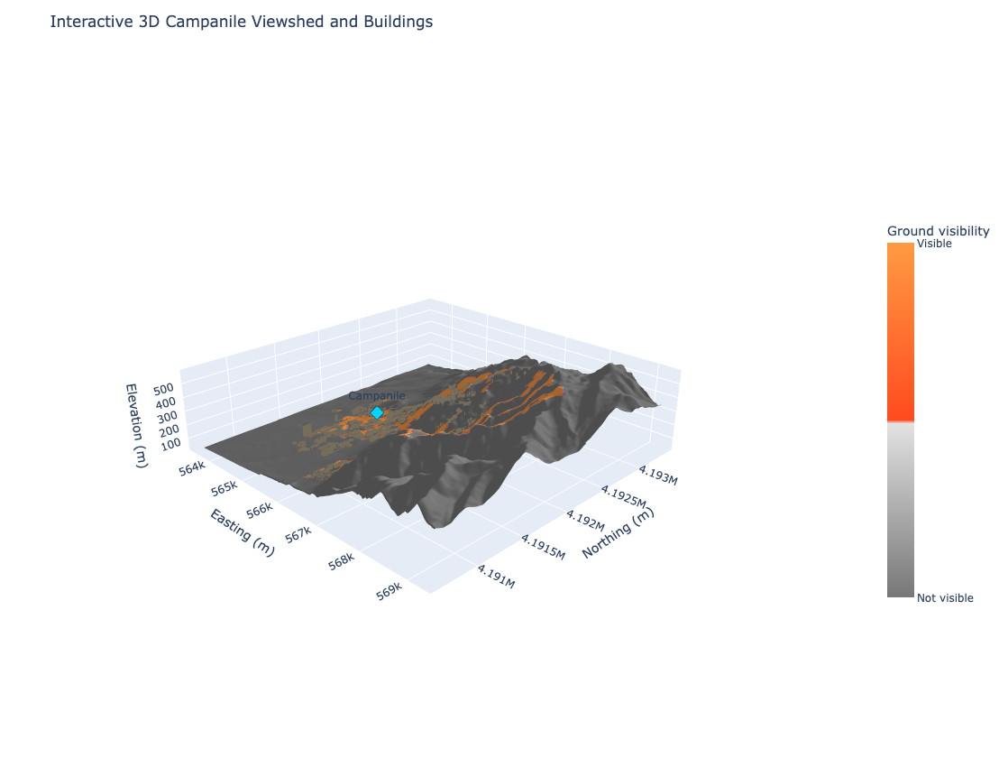

In [32]:
import numpy as np
import geopandas as gpd
import rasterio
import plotly.graph_objects as go
from rasterio.enums import Resampling
from pyproj import Transformer
from shapely.geometry import Polygon, MultiPolygon
with rasterio.open(dem_path) as src:
    max_dim = 350
    scale = min(1, max_dim / max(src.height, src.width))
    out_h = max(2, int(src.height * scale))
    out_w = max(2, int(src.width * scale))

    dem = src.read(
        1,
        out_shape=(out_h, out_w),
        resampling=Resampling.bilinear
    ).astype(float)

    bounds = src.bounds
    dem_crs = src.crs
    nodata = src.nodata
    full_transform = src.transform

    if nodata is not None:
        dem[dem == nodata] = np.nan

with rasterio.open(visible_ground_path) as src:
    visible = src.read(
        1,
        out_shape=(out_h, out_w),
        resampling=Resampling.nearest
    )

x = np.linspace(bounds.left, bounds.right, out_w)
y = np.linspace(bounds.top, bounds.bottom, out_h)
X, Y = np.meshgrid(x, y)

if "buildings" in globals():
    bldg = buildings.copy()
else:
    bldg = gpd.read_file(
        buildings_path,
        layer="buildings"
    )

bldg = bldg.to_crs(dem_crs)

height_candidates = [
    "viewshed_height_m",
    "estimated_height_m",
    "height_m",
    "height"
]
height_col = next(
    (c for c in height_candidates if c in bldg.columns),
    None
)

if height_col is None:
    raise ValueError(
        "No building height field found. Check bldg.columns."
    )

bldg[height_col] = __import__("pandas").to_numeric(
    bldg[height_col], errors="coerce"
)
bldg[height_col] = bldg[height_col].fillna(10).clip(lower=2)

name_col = "name" if "name" in bldg.columns else "building"

transformer = Transformer.from_crs(
    "EPSG:4326", dem_crs, always_xy=True
)
camp_x, camp_y = transformer.transform(-122.2577, 37.8721)

def ground_elevation(px, py):
    col = int((px - bounds.left) / (bounds.right - bounds.left) * (dem.shape[1] - 1))
    row = int((bounds.top - py) / (bounds.top - bounds.bottom) * (dem.shape[0] - 1))

    row = np.clip(row, 0, dem.shape[0] - 1)
    col = np.clip(col, 0, dem.shape[1] - 1)

    z = dem[row, col]
    return float(z) if np.isfinite(z) else float(np.nanmedian(dem))

visible_cells = (visible == 1) & np.isfinite(dem)

surface_colors = np.where(
    visible_cells,
    1,
    0
)

fig = go.Figure()

fig.add_trace(go.Surface(
    x=X,
    y=Y,
    z=dem,
    surfacecolor=surface_colors,
    colorscale=[
        [0.0, "#777777"],
        [0.49, "#E2E2E2"],
        [0.5, "#FF4B1F"],
        [1.0, "#FF9A42"]
    ],
    cmin=0,
    cmax=1,
    showscale=True,
    colorbar=dict(
        title="Ground visibility",
        tickvals=[0, 1],
        ticktext=["Not visible", "Visible"],
        len=0.55
    ),
    connectgaps=False,
    opacity=1,
    lighting=dict(
        ambient=0.65,
        diffuse=0.8,
        specular=0.15,
        roughness=0.8
    ),
    name="Terrain and viewshed",
    hovertemplate=(
        "Easting: %{x:.0f} m<br>"
        "Northing: %{y:.0f} m<br>"
        "Elevation: %{z:.1f} m"
        "<extra>Terrain</extra>"
    )
))

xmin, xmax = bounds.left, bounds.right
ymin, ymax = bounds.bottom, bounds.top
bldg = bldg.cx[xmin:xmax, ymin:ymax]

max_buildings = 2500
if len(bldg) > max_buildings:
    print(
        f"Plotting {max_buildings} of {len(bldg)} buildings "
        "to keep the interactive scene responsive."
    )
    bldg = bldg.copy()

    bldg["_distance"] = bldg.geometry.centroid.distance(
        gpd.GeoSeries(
            [__import__("shapely").geometry.Point(camp_x, camp_y)],
            crs=dem_crs
        ).iloc[0]
    )
    bldg = bldg.sort_values("_distance").head(max_buildings)

building_x, building_y, building_z = [], [], []
building_hover = []

def add_wall(x1, y1, z1, x2, y2, z2, height, label):
    base = min(z1, z2)
    building_x.extend([x1, x2, x2, x1, None])
    building_y.extend([y1, y2, y2, y1, None])
    building_z.extend([base, base, base + height, base + height, None])
    building_hover.extend([label] * 5)

for _, row in bldg.iterrows():
    geom = row.geometry
    if geom is None or geom.is_empty:
        continue

    polygons = (
        list(geom.geoms)
        if geom.geom_type == "MultiPolygon"
        else [geom]
    )

    height = float(row[height_col])
    label = str(row.get(name_col, "Building"))
    label = f"{label}<br>Height: {height:.1f} m"

    for poly in polygons:
        if poly.geom_type != "Polygon":
            continue

        coords = list(poly.exterior.coords)
        for (x1, y1), (x2, y2) in zip(coords[:-1], coords[1:]):
            z1 = ground_elevation(x1, y1)
            z2 = ground_elevation(x2, y2)
            add_wall(x1, y1, z1, x2, y2, z2, height, label)

mesh_x, mesh_y, mesh_z = [], [], []
i_idx, j_idx, k_idx = [], [], []
hover_text = []

for idx in range(0, len(building_x), 5):
    if building_x[idx] is None:
        continue

    base_idx = len(mesh_x)
    mesh_x.extend(building_x[idx:idx+4])
    mesh_y.extend(building_y[idx:idx+4])
    mesh_z.extend(building_z[idx:idx+4])

    i_idx.extend([base_idx, base_idx])
    j_idx.extend([base_idx + 1, base_idx + 2])
    k_idx.extend([base_idx + 2, base_idx + 3])
    hover_text.extend([building_hover[idx]] * 4)

if i_idx:
    fig.add_trace(go.Mesh3d(
        x=mesh_x,
        y=mesh_y,
        z=mesh_z,
        i=i_idx,
        j=j_idx,
        k=k_idx,
        color="#D8C7A5",
        opacity=0.9,
        flatshading=True,
        name="3D building walls",
        hovertext=hover_text,
        hoverinfo="text",
        lighting=dict(
            ambient=0.55,
            diffuse=0.85,
            specular=0.15,
            roughness=0.8
        )
    ))

camp_ground = ground_elevation(camp_x, camp_y)
camp_tower_height = 93.6

fig.add_trace(go.Scatter3d(
    x=[camp_x],
    y=[camp_y],
    z=[camp_ground + camp_tower_height],
    mode="markers+text",
    marker=dict(
        size=7,
        color="#00D5FF",
        symbol="diamond",
        line=dict(color="black", width=2)
    ),
    text=["Campanile"],
    textposition="top center",
    name="Campanile observation point",
    hovertemplate=(
        "Sather Tower<br>"
        "Approx. tower-top elevation: %{z:.1f} m"
        "<extra></extra>"
    )
))

fig.update_layout(
    title="Interactive 3D Campanile Viewshed and Buildings",
    scene=dict(
        xaxis_title="Easting (m)",
        yaxis_title="Northing (m)",
        zaxis_title="Elevation (m)",
        aspectmode="manual",
        aspectratio=dict(x=1, y=1, z=0.25),
        camera=dict(
            eye=dict(x=1.6, y=-1.6, z=1.0)
        )
    ),
    height=850,
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=0.01,
        xanchor="left",
        x=0.01
    )
)

fig.show()

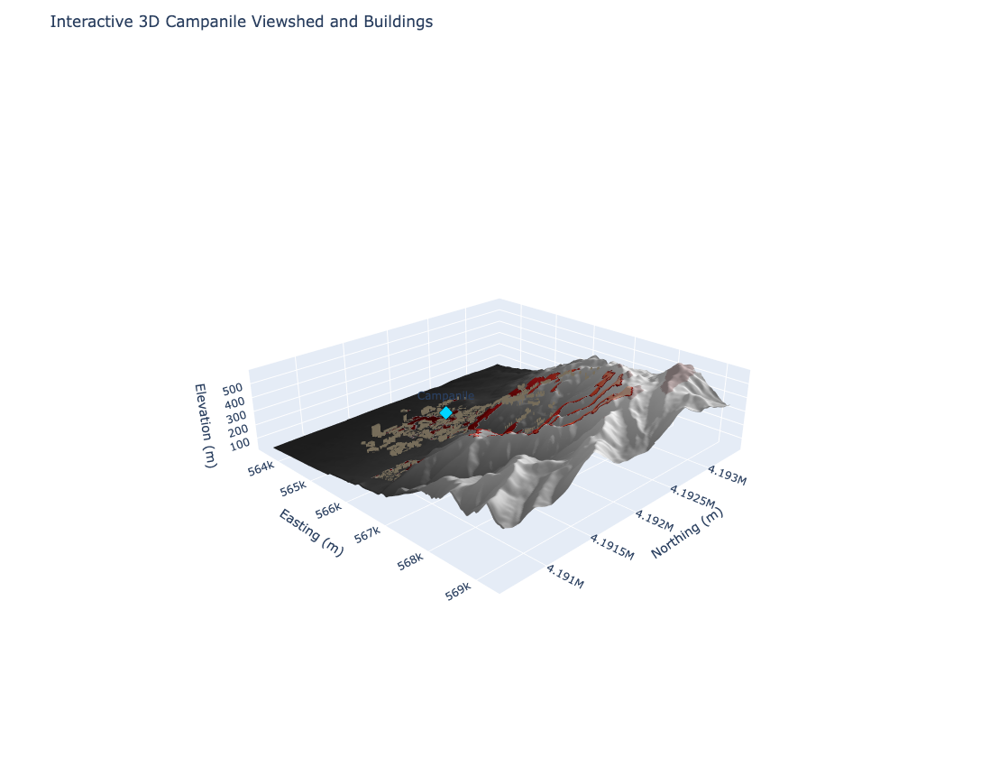

In [33]:
elev_min = np.nanpercentile(dem, 2)
elev_max = np.nanpercentile(dem, 98)

elev_norm = np.clip(
    (dem - elev_min) / max(elev_max - elev_min, 1e-9),
    0, 1
)

gray_scale = [
    [0.0, "#292929"],   # lowest
    [0.25, "#626262"],
    [0.5, "#999999"],
    [0.75, "#CDCDCD"],
    [1.0, "#F5F5F5"]    # highest
]

red_scale = [
    [0.0, "#4A0000"],   # lowest
    [0.25, "#8B0000"],
    [0.5, "#D7191C"],
    [0.75, "#FF5733"],
    [1.0, "#FFD0B5"]    # highest
]
custom_scale = []

for t, color in gray_scale:
    custom_scale.append([t * 0.499, color])

for t, colorin red_scale:
    custom_scale.append([0.501 + t * 0.499, color])

surface_color = np.where(
    visible_cells,
    0.501 + 0.499 * elev_norm,
    0.499 * elev_norm
)

fig.data = fig.data[1:]

fig.add_trace(go.Surface(
    x=X,
    y=Y,
    z=dem,
    surfacecolor=surface_color,
    colorscale=custom_scale,
    cmin=0,
    cmax=1,
    showscale=False,
    connectgaps=False,
    opacity=1,
    lighting=dict(
        ambient=0.55,
        diffuse=0.85,
        specular=0.15,
        roughness=0.8
    ),
    name="Elevation and visibility",
    hovertemplate=(
        "Easting: %{x:.0f} m<br>"
        "Northing: %{y:.0f} m<br>"
        "Elevation: %{z:.1f} m"
        "<extra></extra>"
    )
))

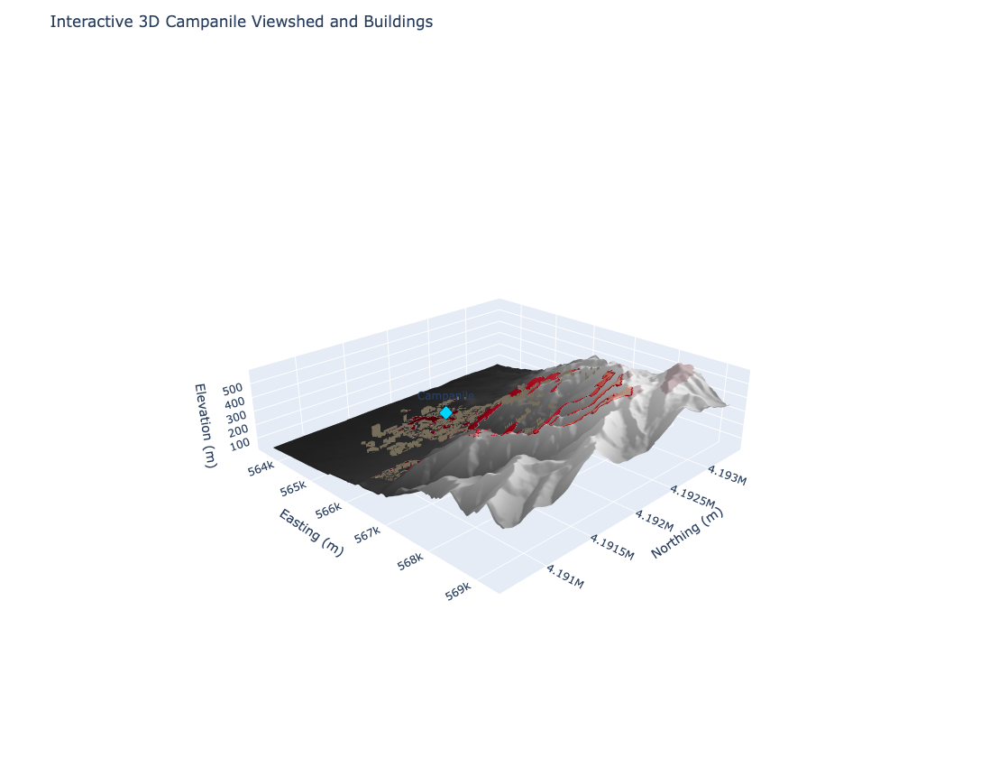

In [34]:
# --------------------------------------------------
# Glowing red viewshed + grayscale elevation
# --------------------------------------------------

# Normalize elevation for consistent gradients
elev_min = np.nanpercentile(dem, 2)
elev_max = np.nanpercentile(dem, 98)

elev_norm = np.clip(
    (dem - elev_min) / max(elev_max - elev_min, 1e-9),
    0, 1
)

# Non-visible terrain: charcoal to silver
gray_scale = [
    [0.0, "#242424"],
    [0.25, "#505050"],
    [0.5, "#898989"],
    [0.75, "#C4C4C4"],
    [1.0, "#F0F0F0"]
]

# Visible terrain: deep crimson to luminous coral
red_scale = [
    [0.0, "#4A0008"],
    [0.2, "#990014"],
    [0.4, "#E00020"],
    [0.6, "#FF263F"],
    [0.8, "#FF684F"],
    [1.0, "#FFD0B8"]
]

custom_scale = []
for t, color in gray_scale:
    custom_scale.append([t * 0.499, color])

for t, color in red_scale:
    custom_scale.append([0.501 + t * 0.499, color])

surface_color = np.where(
    visible_cells,
    0.501 + 0.499 * elev_norm,
    0.499 * elev_norm
)

# Remove the existing terrain trace only
terrain_idx = next(
    (i for i, trace in enumerate(fig.data)
     if trace.type == "surface"),
    None
)
if terrain_idx is not None:
    fig.data = tuple(
        trace for i, trace in enumerate(fig.data)
        if i != terrain_idx
    )

fig.add_trace(go.Surface(
    x=X,
    y=Y,
    z=dem,
    surfacecolor=surface_color,
    colorscale=custom_scale,
    cmin=0,
    cmax=1,
    showscale=False,
    connectgaps=False,
    opacity=1,
    lighting=dict(
        ambient=0.7,
        diffuse=0.9,
        specular=0.35,
        roughness=0.45,
        fresnel=0.25
    ),
    name="Glowing viewshed",
    hovertemplate=(
        "Elevation: %{z:.1f} m"
        "<extra></extra>"
    )
))

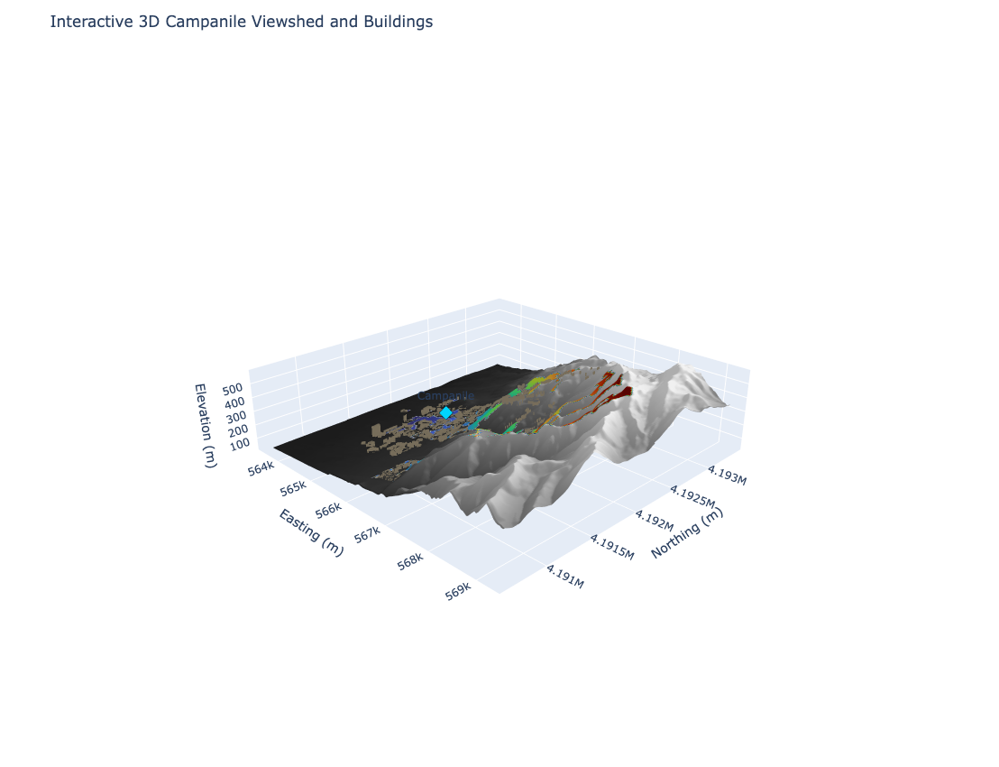

In [39]:

gray_scale = [
    [0.00, "#202020"],
    [0.20, "#414141"],
    [0.40, "#696969"],
    [0.60, "#969696"],
    [0.80, "#C5C5C5"],
    [1.00, "#F0F0F0"],
]

turbo_palette = [
    [0.00, "#30123b"],
    [0.10, "#4662d7"],
    [0.20, "#35abf8"],
    [0.30, "#1be5b5"],
    [0.40, "#61fc6c"],
    [0.50, "#c8ef34"],
    [0.60, "#faba39"],
    [0.70, "#f66b19"],
    [0.80, "#d93806"],
    [0.90, "#a01805"],
    [1.00, "#7a0403"],
]

custom_scale = []

for t, color in gray_scale:
    custom_scale.append([t * 0.49, color])

for t, color in turbo_palette:
    custom_scale.append([0.51 + t * 0.49, color])

elev_min = np.nanpercentile(dem, 2)
elev_max = np.nanpercentile(dem, 98)

elev_norm = np.clip(
    (dem - elev_min) / max(elev_max - elev_min, 1e-9),
    0,
    1
)

surface_color = np.where(
    visible_cells,
    0.51 + 0.49 * elev_norm,
    0.49 * elev_norm
)

fig.data = tuple(
    trace for trace in fig.data
    if trace.type != "surface"
)

fig.add_trace(
    go.Surface(
        x=X,
        y=Y,
        z=dem,
        surfacecolor=surface_color,
        colorscale=custom_scale,
        cmin=0,
        cmax=1,
        showscale=False,
        connectgaps=False,
        opacity=1,
        lighting=dict(
            ambient=0.72,
            diffuse=0.85,
            specular=0.12,
            roughness=0.85
        ),
        name="Terrain and Turbo viewshed",
        hovertemplate="Elevation: %{z:.1f} m<extra></extra>"
    )
)

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_30365/3449712545.py:42: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  terrain = src.read(1)


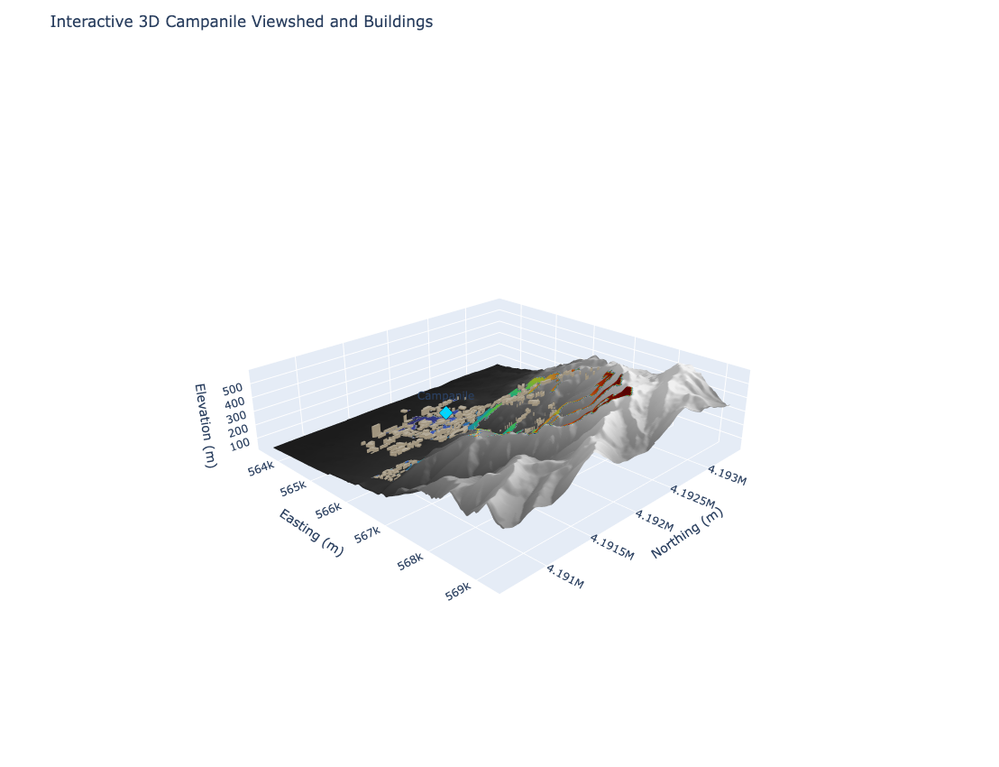

In [40]:
import numpy as np
import geopandas as gpd
import plotly.graph_objects as go
from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import triangulate

buildings_3d = buildings.to_crs(dem_crs).copy()

height_col = next(
    (
        c for c in [
            "viewshed_height_m",
            "estimated_height_m",
            "height_m",
            "height"
        ]
        if c in buildings_3d.columns
    ),
    None
)

if height_col is None:
    raise ValueError("No building height column was found.")

buildings_3d[height_col] = (
    buildings_3d[height_col]
    .fillna(10)
    .clip(lower=2)
)

import rasterio
from rasterio.transform import rowcol

with rasterio.open(dem_path) as src:
    terrain = src.read(1)
    terrain_transform = src.transform
    terrain_nodata = src.nodata

def sample_ground(x, y):
    r, c = rowcol(terrain_transform, x, y)

    if 0 <= r < terrain.shape[0] and 0 <= c < terrain.shape[1]:
        z = float(terrain[r, c])

        if np.isfinite(z) and (terrain_nodata is None or z != terrain_nodata):
            return z

    return float(np.nanmedian(terrain))

fig.data = tuple(
    trace for trace in fig.data
    if not (trace.type == "mesh3d" and trace.name == "3D Buildings")
)

wall_x, wall_y, wall_z = [], [], []
wall_i, wall_j, wall_k = [], [], []

roof_x, roof_y, roof_z = [], [], []
roof_i, roof_j, roof_k = [], [], []

def add_polygon_3d(poly, height):
    """Build triangulated vertical walls and a flat roof."""
    if poly.is_empty or poly.area == 0:
        return

    coords = list(poly.exterior.coords)[:-1]
    if len(coords) < 3:
        return

    ground_z = [sample_ground(x, y) for x, y in coords]
    top_z = [z + height for z in ground_z]

    start = len(wall_x)

    for n, (x, y) in enumerate(coords):
        nxt = (n + 1) % len(coords)

        wall_x.extend([x, coords[nxt][0], coords[nxt][0], x])
        wall_y.extend([y, coords[nxt][1], coords[nxt][1], y])
        wall_z.extend([ground_z[n], ground_z[nxt], top_z[nxt], top_z[n]])

        base = len(wall_x) - 4
        wall_i.extend([base, base])
        wall_j.extend([base + 1, base + 2])
        wall_k.extend([base + 2, base + 3])

    for tri in triangulate(poly):
        if not poly.covers(tri.representative_point()):
            continue

        tri_coords = list(tri.exterior.coords)[:3]
        tri_ground = [sample_ground(x, y) for x, y in tri_coords]
        tri_top = [z + height for z in tri_ground]

        idx = len(roof_x)
        for (x, y), z in zip(tri_coords, tri_top):
            roof_x.append(x)
            roof_y.append(y)
            roof_z.append(z)

        roof_i.append(idx)
        roof_j.append(idx + 1)
        roof_k.append(idx + 2)

for _, row in buildings_3d.iterrows():
    geom = row.geometry
    height = float(row[height_col])

    if geom is None or geom.is_empty:
        continue

    if isinstance(geom, Polygon):
        add_polygon_3d(geom, height)

    elif isinstance(geom, MultiPolygon):
        for part in geom.geoms:
            add_polygon_3d(part, height)

fig.add_trace(
    go.Mesh3d(
        x=wall_x, y=wall_y, z=wall_z,
        i=wall_i, j=wall_j, k=wall_k,
        color="#C8B99E",
        opacity=1,
        flatshading=True,
        showscale=False,
        name="3D Buildings",
        hoverinfo="skip"
    )
)

fig.add_trace(
    go.Mesh3d(
        x=roof_x, y=roof_y, z=roof_z,
        i=roof_i, j=roof_j, k=roof_k,
        color="#E4D8C3",
        opacity=1,
        flatshading=True,
        showscale=False,
        name="Building Roofs",
        hoverinfo="skip"
    )
)

Nearest footprint distance: 7.07 m
Building name: The Campanile (Sather Tower)


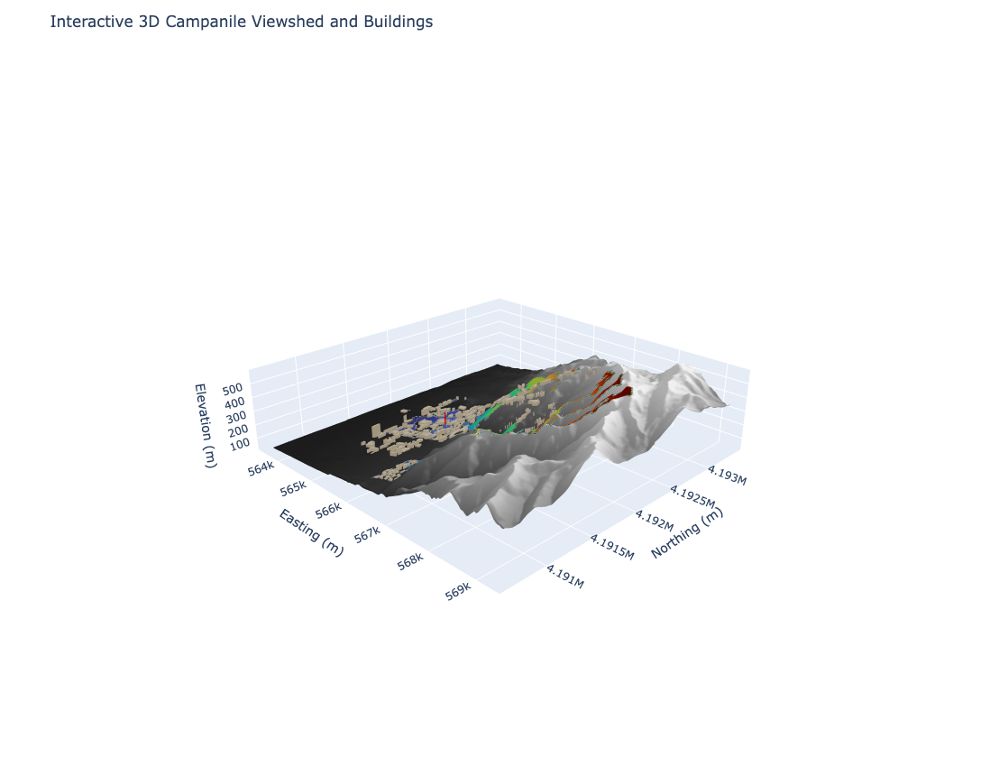

In [43]:
from shapely.geometry import Point
import numpy as np
import plotly.graph_objects as go

campanile_lon = -122.2577
campanile_lat = 37.8721
campanile_height = 93.6
campanile_point = gpd.GeoSeries(
    [Point(campanile_lon, campanile_lat)],
    crs="EPSG:4326"
).to_crs(dem_crs).iloc[0]

cx, cy = campanile_point.x, campanile_point.y
camp_ground = sample_ground(cx, cy)
camp_distances = buildings_3d.geometry.distance(campanile_point)
camp_idx = camp_distances.idxmin()
camp_building = buildings_3d.loc[camp_idx]
camp_geom = camp_building.geometry
print("Nearest footprint distance:", round(camp_distances.loc[camp_idx], 2), "m")
print("Building name:", camp_building.get("name", "Unknown"))
camp_height = float(camp_building[height_col])
camp_height = max(camp_height, campanile_height)
other_buildings = buildings_3d.drop(index=camp_idx)
camp_wall_x, camp_wall_y, camp_wall_z = [], [], []
camp_wall_i, camp_wall_j, camp_wall_k = [], [], []
camp_roof_x, camp_roof_y, camp_roof_z = [], [], []
camp_roof_i, camp_roof_j, camp_roof_k = [], [], []

def add_campanile_part(poly, height):
    coords = list(poly.exterior.coords)[:-1]
    if len(coords) < 3:
        return

    base_z = [sample_ground(x, y) for x, y in coords]
    top_z = [z + height for z in base_z]
    for n in range(len(coords)):
        nxt = (n + 1) % len(coords)
        b = len(camp_wall_x)

        camp_wall_x.extend([coords[n][0], coords[nxt][0],
                            coords[nxt][0], coords[n][0]])
        camp_wall_y.extend([coords[n][1], coords[nxt][1],
                            coords[nxt][1], coords[n][1]])
        camp_wall_z.extend([base_z[n], base_z[nxt],
                            top_z[nxt], top_z[n]])

        camp_wall_i.extend([b, b])
        camp_wall_j.extend([b + 1, b + 2])
        camp_wall_k.extend([b + 2, b + 3])
    from shapely.ops import triangulate
    for tri in triangulate(poly):
        if not poly.covers(tri.representative_point()):
            continue
        tri_coords = list(tri.exterior.coords)[:3]
        tri_z = [sample_ground(x, y) + height for x, y in tri_coords]
        b = len(camp_roof_x)

        for (x, y), z in zip(tri_coords, tri_z):
            camp_roof_x.append(x)
            camp_roof_y.append(y)
            camp_roof_z.append(z)

        camp_roof_i.append(b)
        camp_roof_j.append(b + 1)
        camp_roof_k.append(b + 2)

if camp_geom.geom_type == "Polygon":
    add_campanile_part(camp_geom, camp_height)
elif camp_geom.geom_type == "MultiPolygon":
    for part in camp_geom.geoms:
        add_campanile_part(part, camp_height)
fig.add_trace(go.Mesh3d(
    x=camp_wall_x, y=camp_wall_y, z=camp_wall_z,
    i=camp_wall_i, j=camp_wall_j, k=camp_wall_k,
    color="#FF1010",
    opacity=1,
    flatshading=True,
    showscale=False,
    name="Campanile",
    hovertemplate="Sather Tower (Campanile)<extra></extra>"
))
fig.add_trace(go.Mesh3d(
    x=camp_roof_x, y=camp_roof_y, z=camp_roof_z,
    i=camp_roof_i, j=camp_roof_j, k=camp_roof_k,
    color="#FF2020",
    opacity=1,
    flatshading=True,
    showscale=False,
    name="Campanile Roof",
    hoverinfo="skip"
))

theta = np.linspace(0, 2 * np.pi, 80)
radii = [12, 22, 34]          # Buffer radii in metres
opacities = [0.20, 0.11, 0.055]

for radius, opacity in zip(radii, opacities):
    gx = cx + radius * np.cos(theta)
    gy = cy + radius * np.sin(theta)

    gz = np.array([sample_ground(x, y) + 0.8 for x, y in zip(gx, gy)])

    x_fill = np.concatenate(([cx], gx, [gx[0]]))
    y_fill = np.concatenate(([cy], gy, [gy[0]]))
    z_fill = np.concatenate(([camp_ground + 0.8], gz, [gz[0]]))

    ii, jj, kk = [], [], []
    for j in range(1, len(x_fill) - 1):
        ii.append(0)
        jj.append(j)
        kk.append(j + 1)

    fig.add_trace(go.Mesh3d(
        x=x_fill, y=y_fill, z=z_fill,
        i=ii, j=jj, k=kk,
        color="#FF1515",
        opacity=opacity,
        flatshading=False,
        showscale=False,
        name="Campanile Glow",
        hoverinfo="skip"
    ))

fig.data = tuple(
    trace for trace in fig.data
    if not (
        trace.type == "scatter3d"
        and trace.mode
        and "markers" in trace.mode
        and trace.name
        and "campanile" in trace.name.lower()
    )
)

fig.show()

In [101]:

import numpy as np
import plotly.graph_objects as go

SUN_AZIMUTH = 315      # degrees clockwise from north
SUN_ALTITUDE = 35      # degrees above the horizon
VERTICAL_EXAGGERATION = 1.0

z = np.asarray(dem, dtype=float)

dx = float(np.nanmedian(np.abs(np.diff(X, axis=1))))
dy = float(np.nanmedian(np.abs(np.diff(Y, axis=0))))

if not np.isfinite(dx) or dx <= 0:
    dx = 1.0
if not np.isfinite(dy) or dy <= 0:
    dy = 1.0

dz_dy, dz_dx = np.gradient(z * VERTICAL_EXAGGERATION, dy, dx)

slope = np.arctan(np.sqrt(dz_dx**2 + dz_dy**2))
aspect = np.arctan2(-dz_dx, dz_dy)

azimuth = np.radians(SUN_AZIMUTH)
altitude = np.radians(SUN_ALTITUDE)

illumination = (
    np.sin(altitude) * np.cos(slope)
    + np.cos(altitude) * np.sin(slope)
    * np.cos(azimuth - aspect)
)

hillshade = np.clip(illumination, 0, 1)
hillshade = 0.18 + 0.82 * hillshade

hillshade[~np.isfinite(z)] = 0.18

print(f"Hillshade calculated using sun azimuth {SUN_AZIMUTH}°")
print(f"Sun altitude: {SUN_ALTITUDE}°")
print(f"Grid spacing: {dx:.2f} m × {dy:.2f} m")



# turbo_palette = [
#     [0.00, "#30123b"],
#     [0.10, "#4662d7"],
#     [0.20, "#35abf8"],
#     [0.30, "#1be5b5"],
#     [0.40, "#61fc6c"],
#     [0.50, "#c8ef34"],
#     [0.60, "#faba39"],
#     [0.70, "#f66b19"],
#     [0.80, "#d93806"],
#     [0.90, "#a01805"],
#     [1.00, "#7a0403"],
# ]

# turbo_palette = [
#     [0.00, "#012F58"],  
#     [0.10, "#023E75"],
#     [0.20, "#024E92"],
#     [0.30, "#025EAF"],
#     [0.40, "#036ECC"],
#     [0.50, "#037EE9"],
#     [0.60, "#038EFC"],
#     [0.70, "#2B9EFC"],
#     [0.80, "#54AEFD"],
#     [0.90, "#7DBEFD"],
#     [1.00, "#A6CEFE"],
# ]

turbo_palette = [
    [0.00, "#012F58"], 
    [0.10, "#02396B"],
    [0.20, "#02447E"],
    [0.30, "#024F91"],
    [0.40, "#0259A4"],
    [0.50, "#0364B7"],
    [0.60, "#036ECA"],
    [0.70, "#0379DD"],
    [0.80, "#0383F0"],
    [0.90, "#1990FD"],
    [1.00, "#309CFC"],  
]




gray_scale = [
    [0.00, "#F2F2F2"],
    [0.10, "#DBDBDB"],
    [0.20, "#C4C4C4"],
    [0.30, "#A9A9A9"],
    [0.40, "#969696"],
    [0.50, "#808080"],
    [0.60, "#696969"],
    [0.70, "#525252"],
    [0.80, "#3B3B3B"],
    [0.90, "#333333"],
    [1.00, "#262626"],
]

custom_scale = []

for t, color in gray_scale:
    custom_scale.append([t * 0.49, color])

for t, color in turbo_palette:
    custom_scale.append([0.51 + t * 0.49, color])


visible = np.asarray(visible_cells, dtype=bool)

if visible.shape != z.shape:
    raise ValueError(
        f"visible_cells shape {visible.shape} does not match "
        f"dem shape {z.shape}. Use the visibility mask corresponding "
        "to the displayed DEM grid."
    )

valid = np.isfinite(z)

z_min = float(np.nanmin(z))
z_max = float(np.nanmax(z))

if z_max > z_min:
    elev_norm = np.clip((z - z_min) / (z_max - z_min), 0, 1)
else:
    elev_norm = np.zeros_like(z)

surface_color = np.where(
    visible,
    0.51 + 0.49 * elev_norm,
    0.49 * hillshade
)







import numpy as np
from scipy.ndimage import gaussian_filter


BLUR_SIGMA = 0.9

FADE_STRENGTH = 1.0

visible = np.asarray(visible_cells, dtype=float)

soft_visibility = gaussian_filter(
    visible,
    sigma=BLUR_SIGMA,
    mode="nearest"
)

soft_visibility = np.clip(soft_visibility, 0, 1)

soft_visibility = soft_visibility ** (1 / FADE_STRENGTH)


elev_norm = np.clip(
    (dem - np.nanmin(dem)) /
    (np.nanmax(dem) - np.nanmin(dem)),
    0, 1
)

gray_color = 0.49 * hillshade

turbo_color = 0.51 + 0.49 * elev_norm

surface_color = (
    (1 - soft_visibility) * gray_color
    + soft_visibility * turbo_color
)

surface_color[~np.isfinite(dem)] = 0


terrain_trace_index = next(
    (
        i for i, trace in enumerate(fig.data)
        if trace.type == "surface"
    ),
    None
)

if terrain_trace_index is None:
    raise ValueError(
        "No terrain surface found in fig. Run your hillshade "
        "terrain creation cell first."
    )

fig.data[terrain_trace_index].surfacecolor = surface_color

fig.show()










surface_color[~valid] = 0

fig.data = tuple(
    trace for trace in fig.data
    if trace.type != "surface"
)

fig.add_trace(go.Surface(
    x=X,
    y=Y,
    z=dem,
    surfacecolor=surface_color,
    colorscale=custom_scale,
    cmin=0,
    cmax=1,
    showscale=False,
    connectgaps=False,
    opacity=1,
    name="3DEP hillshade and viewshed",
    hovertemplate=(
        "Easting: %{x:.1f} m<br>"
        "Northing: %{y:.1f} m<br>"
        "Elevation: %{z:.1f} m"
        "<extra></extra>"
    ),
    lighting=dict(
        ambient=0.8,
        diffuse=0.35,
        specular=0.05,
        roughness=1,
        fresnel=0.05
    ),
    lightposition=dict(
        x=-1000 * np.sin(azimuth),
        y=1000 * np.cos(azimuth),
        z=1000 * np.tan(altitude)
    )
))

for trace in fig.data:
    name = (trace.name or "").lower()

    if trace.type != "mesh3d":
        continue

    if "campanile" in name or "sather" in name:
        continue

   
    if "wall" in name:
        trace.color = "#787878"
    elif "roof" in name:
        trace.color = "#A6A6A6"
    else:
        trace.color = "#919191"

    trace.opacity = 1


fig.update_layout(
    title=(
        "VIEWSHED ANALYSIS TO THE CAMPANILE ACROSS UC BERKELEY CAMPUS"
    ),
    scene=dict(
        xaxis_title="Easting (m)",
        yaxis_title="Northing (m)",
        zaxis_title="Elevation (m)",
        aspectmode="data",
        bgcolor="#202020"
    ),
    paper_bgcolor="#202020",
    font=dict(color="white")
)

fig.show()


Hillshade calculated using sun azimuth 315°
Sun altitude: 35°
Grid spacing: 16.45 m × 16.53 m


# EXPORTING

In [103]:
import os

output_dir = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs"
)

os.makedirs(output_dir, exist_ok=True)

html_path = os.path.join(
    output_dir,
    "berkeley_3d_interactive_map.html"
)

fig.write_html(
    html_path,
    include_plotlyjs=True,
    full_html=True,
    auto_open=False,
    config={
        "scrollZoom": True,
        "displayModeBar": True,
        "responsive": True
    }
)

print("Interactive map exported to:")
print(html_path)

Interactive map exported to:
/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_3d_interactive_map.html
